In [1]:
#input necessary functions
import os

import csv
import matplotlib.pyplot as plt
import numpy as np
import numpy #todo-redundant import
import pandas as pd
import random
import shutil
import torch
import xml.etree.ElementTree as ET

# Acquisition function
from botorch.acquisition import qLogExpectedImprovement
from botorch.sampling.stochastic_samplers import StochasticSampler
from botorch.utils.transforms import unnormalize
from botorch.optim import optimize_acqf

from skopt import gp_minimize
from skopt.plots import plot_convergence, plot_objective, plot_evaluations
from skopt.space import Real
from skopt.utils import use_named_args

#Sobol sequence generate initial locations
from torch.quasirandom import SobolEngine
from botorch.utils.transforms import unnormalize

### GP model surrogate
import gpytorch # todo:do we need full package import?
from botorch import fit_gpytorch_mll
from gpytorch.likelihoods import GaussianLikelihood
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.means.mean import Mean
from botorch.models import SingleTaskGP
from botorch.models.transforms import Standardize
from botorch.utils.transforms import normalize
from gpytorch.constraints import Interval
from gpytorch.kernels import MaternKernel, ScaleKernel, RBFKernel, Kernel, rbf_kernel

# we may no longer  need these
import math
from gpytorch.functions import MaternCovariance
from gpytorch.settings import trace_mode
import copy 

from sklearn.model_selection import train_test_split

from src.error_function import ErrorFunction
from src.error_function_route_version import ErrorFunctionRouteVersion
from src.fA_functions import FaFunction,PolynomialFaFunction,FaFunctionTT, FaFunction_fftt,FAFunctionLinearRegresion
from src.feasibility_check import check_feasibility
from src.freeflow_eta import get_freeflow_eta
from src.gp_initialization import InitializeGPModel
from src.green_time_functions import map_to_all_green_times,update_green_time_dict,update_green_times
from src.initial_samples import InitialSamples
from src.kernels import CustomKernelwMatern,MaternKernel_v4,Default_MaternKernel_v4,CustomPolynomial, MaternKernel_v4_mean,CustomKernelwMatern,Linear_Regression
from src.mean_functions import CustomMean
from src.objective_function import objective
from src.optimization import Optimization
from src.sumo_run import SumoRun
from src.bo_loop import BOLoop
from src.dataset_creation import FixedDemandDataset
from src.edges_green_time import EdgesGreenTime
from src.incoming_corridors import TLIncomingCorridors
from src.routes_green_time_tensor_version_x_init import RoutesGreenTimeTensor
from src.updated_fA_function_tensor_version import UpdatedFAFunctionLinearRegresion

import sumolib

from src.complete_corridors_connexions import CompleteCorridorsConnexions
from src.connexions_green_time import ConnexionsGreenTime
from src.connexions_routes_correspondance import connexions_routes_correspondance_matrix

from scipy.stats import ecdf



c:\Users\sh032\anaconda3\envs\thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Creation of the Ground Truth dataframe

In [2]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"
ADD_XML_GT = "ingolstadt7/additional.gt_scenario.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

In [3]:
def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET

['gneJ260',
 'gneJ210',
 '32564122',
 'gneJ207',
 'gneJ143',
 'cluster_1757124350_1757124352',
 'cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190']

In [4]:
sumo_runner_gt=SumoRun(
    add_xml=ADD_XML_GT,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

g_vec_gt=np.array([38,38,42,38,38,38,36])

sumo_runner_gt.sumo_run_parse_data(g_vec_gt, epoch_indx="gt_route_file")

C:\Program Files (x86)\Eclipse\Sumo\tools\traci\main.py:200: UserWarning: API change now handles step as floating point seconds
  connection.check().simulationStep(step)
C:\Program Files (x86)\Eclipse\Sumo\tools\traci\main.py:200: UserWarning: API change now handles step as floating point seconds
  connection.check().simulationStep(step)
C:\Program Files (x86)\Eclipse\Sumo\tools\traci\main.py:200: UserWarning: API change now handles step as floating point seconds
  connection.check().simulationStep(step)
C:\Program Files (x86)\Eclipse\Sumo\tools\traci\main.py:200: UserWarning: API change now handles step as floating point seconds
  connection.check().simulationStep(step)
C:\Program Files (x86)\Eclipse\Sumo\tools\traci\main.py:200: UserWarning: API change now handles step as floating point seconds
  connection.check().simulationStep(step)


,edge_id,average_traveltime,average_traveltime_std
0,-104010328,8.572,0.240770
1,-164051413,0.956,0.005477
2,-173169611#0,22.534,0.723346
3,-201089423#1,24.306,2.805277
4,-201089423#2,6.600,0.972882
...,...,...,...
87,51857517#0,2.368,0.025884
88,51857517#0.33,3.494,0.140641
89,51857517#1,6.396,0.148593
90,51857518#1,5.132,0.023875


# Creation of the initial sample

In [ ]:
ADD_XML = "ingolstadt7/additional.xml"
X_DIM=7
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
print(TL_IDS_SET)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                    [up_bound]*(X_DIM-1)+[50]], 
                    device=device, dtype=dtype)


sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)


initial_sampler=InitialSamples(
    dtype=dtype
)

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

NUM_RESTARTS = 5
INIT_SAMPLE_SIZE = 5


error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                                         df_gt=DF_GT,
                                         sumo_runner=sumo_runner,
                                         corridors_df=corridors_df)

init_sample_x_norm = []
init_sample_y = []
init_df = []
for j1 in range(NUM_RESTARTS):
    x_sample, y_sample, df_init = initial_sampler.get_initial_sample(INIT_SAMPLE_SIZE, X_DIM, bounds,error_function)
    init_sample_x_norm.append(x_sample)
    init_sample_y.append(y_sample)
    init_df.append(df_init)

torch.save(init_sample_x_norm,"./init_samples/init_sample_x_norm_route_error_route_file.pt")
torch.save(init_sample_y,"./init_samples/init_sample_y_route_error_route_file.pt")
torch.save(init_df,"./init_samples/init_df_route_error_route_file.pt")

# Linear Regression Kernel ConstantMean Mean

In [2]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [3]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [4]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["ConstantMean"],annotation="nu_2.5_route_error_route_file_original")

# Linear regression Only fA kernel Constant Mean

In [17]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [18]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [19]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["ConstantMean"],annotation="nu_2.5_route_error_route_file_original")

# Linear Regression Kernel Linear Regression Mean

In [21]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [22]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [23]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["linear_regression"],annotation="nu_2.5_route_error_route_file_original")

# Matern Kernel default Linear Regression Mean

In [25]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [26]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [27]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["linear_regression"],annotation="nu_2.5_route_error_route_file_original")

# Only fA Linear Regression Kernel Linear Regression Mean

In [2]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [3]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [4]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["linear_regression"],annotation="nu_2.5_route_error_route_file_original")

In [6]:
fA_function.coeffs

(-6.40621988,
 85.7352254,
 -7.41941697,
 11.0365529,
 0.186797158,
 0.404908884,
 -0.000279010501,
 -12.0503437)

# Default version

In [7]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [8]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [9]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["ConstantMean"],annotation="nu_2.5_route_error_route_file_original")

# Comparison between all versions

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,3988.066253,2705.002327
1,1.0,2642.534153,3137.550080
2,2.0,802.975129,1202.845310
3,3.0,273.206894,107.351319
4,4.0,206.500006,93.369636
5,5.0,199.524516,85.109675
6,6.0,169.352107,59.981392
7,7.0,133.486821,42.219117
8,8.0,133.486821,42.219117
9,9.0,120.956125,42.664508


agg df for Matern Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,3988.066253,2705.002327
1,1.0,887.826036,608.299953
2,2.0,411.708818,241.152927
3,3.0,407.754670,239.177155
4,4.0,382.912791,234.137204
5,5.0,354.332601,243.465101
6,6.0,292.758293,120.943466
7,7.0,238.535025,123.537224
8,8.0,238.535025,123.537224
9,9.0,236.944304,124.259311


agg df for Only fA LR Kernel (2.5) - LR  Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,3988.066253,2705.002327
1,1.0,1891.621351,2683.266730
2,2.0,152.207500,46.533791
3,3.0,141.123296,45.648599
4,4.0,140.970580,45.760933
5,5.0,117.152066,16.052689
6,6.0,111.981808,22.686014
7,7.0,111.981808,22.686014
8,8.0,111.981808,22.686014
9,9.0,103.753355,15.268548


... (2 outputs left out)

agg df for Only fA LR Kernel (2.5) - Constant Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,3988.066253,2705.002327
1,1.0,3856.911663,2908.439018
2,2.0,3856.911663,2908.439018
3,3.0,2934.509200,3141.238961
4,4.0,2512.501573,3243.587337
5,5.0,2512.501573,3243.587337
6,6.0,1012.742742,1131.673799
7,7.0,1012.742742,1131.673799
8,8.0,786.519008,665.630463
9,9.0,601.356981,371.945496


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,3988.066253,2705.002327
1,1.0,1948.451928,1977.022284
2,2.0,1575.866122,2053.232821
3,3.0,718.926544,597.405973
4,4.0,718.926544,597.405973
5,5.0,685.296393,633.883594
6,6.0,685.296393,633.883594
7,7.0,677.937943,639.385441
8,8.0,677.937943,639.385441
9,9.0,677.937943,639.385441


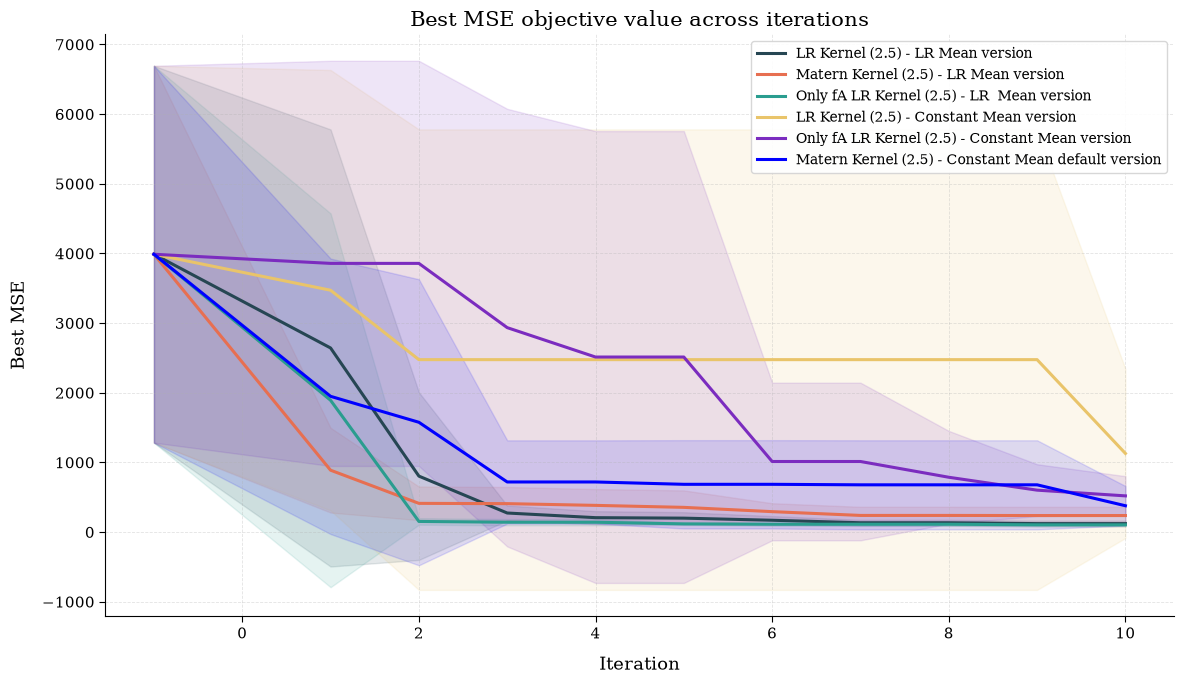

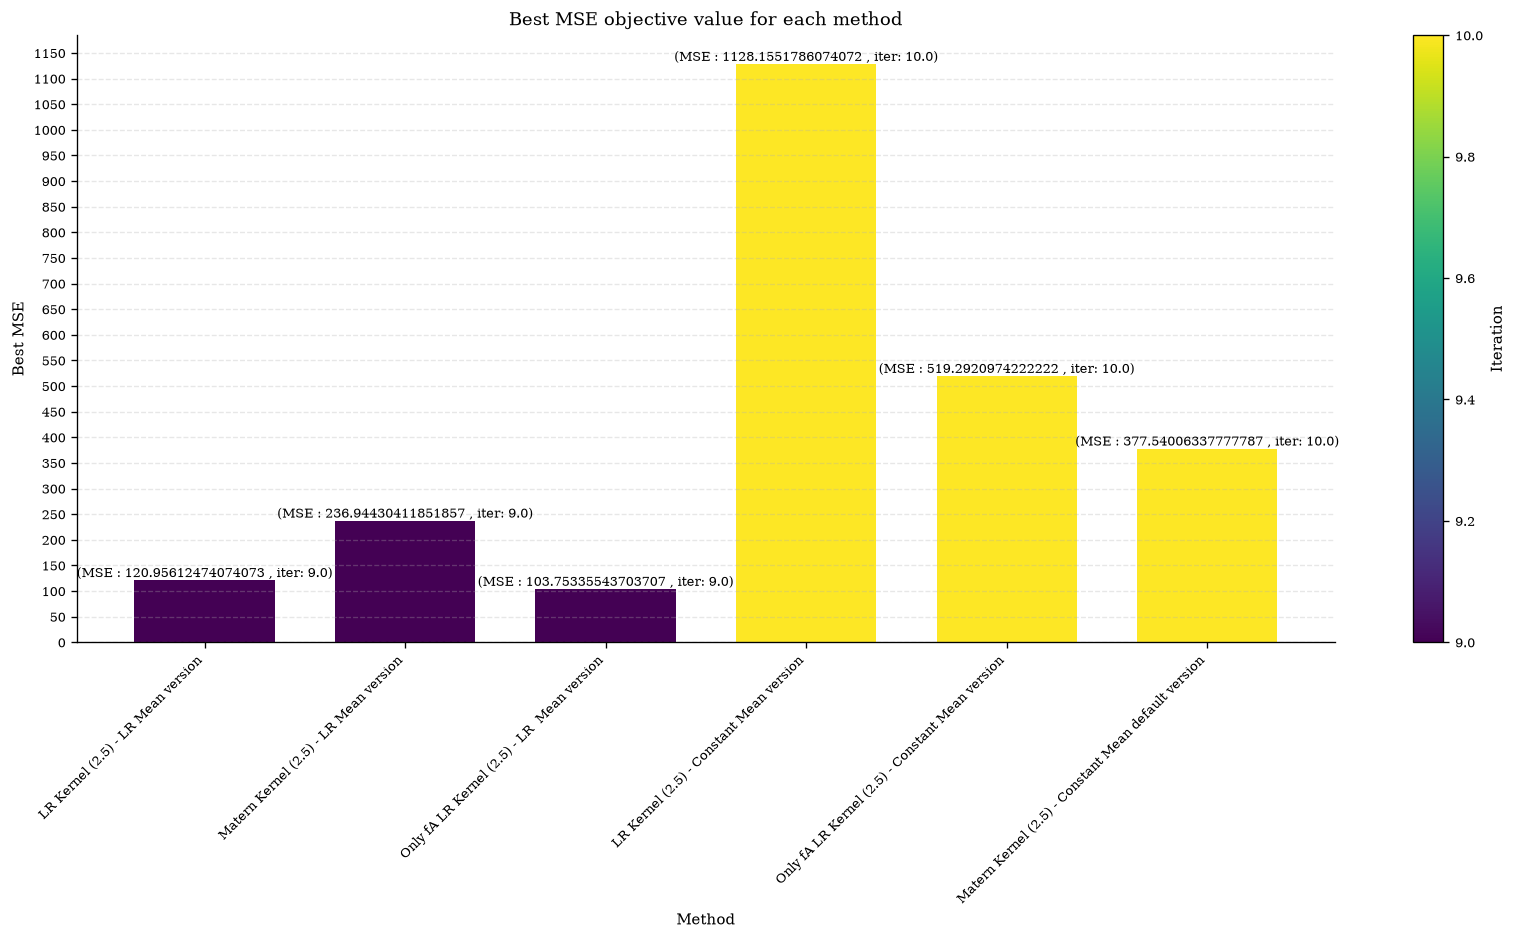

In [29]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - LR Mean version": "#E76F51",
    "Only fA LR Kernel (2.5) - LR  Mean version": "#2A9D8F",
    "LR Kernel (2.5) - Constant Mean version": "#E9C46A",
    "Only fA LR Kernel (2.5) - Constant Mean version": "#7B2CBF",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(5):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - LR Mean version":0,
        "Only fA LR Kernel (2.5) - LR  Mean version":0,
        "LR Kernel (2.5) - Constant Mean version":0,
        "Only fA LR Kernel (2.5) - Constant Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective value across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Iteration", fontsize=9)
cbar.ax.tick_params(labelsize=8)

for bar, iteration,min_value in zip(bars, iterations,min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value} , iter: {iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

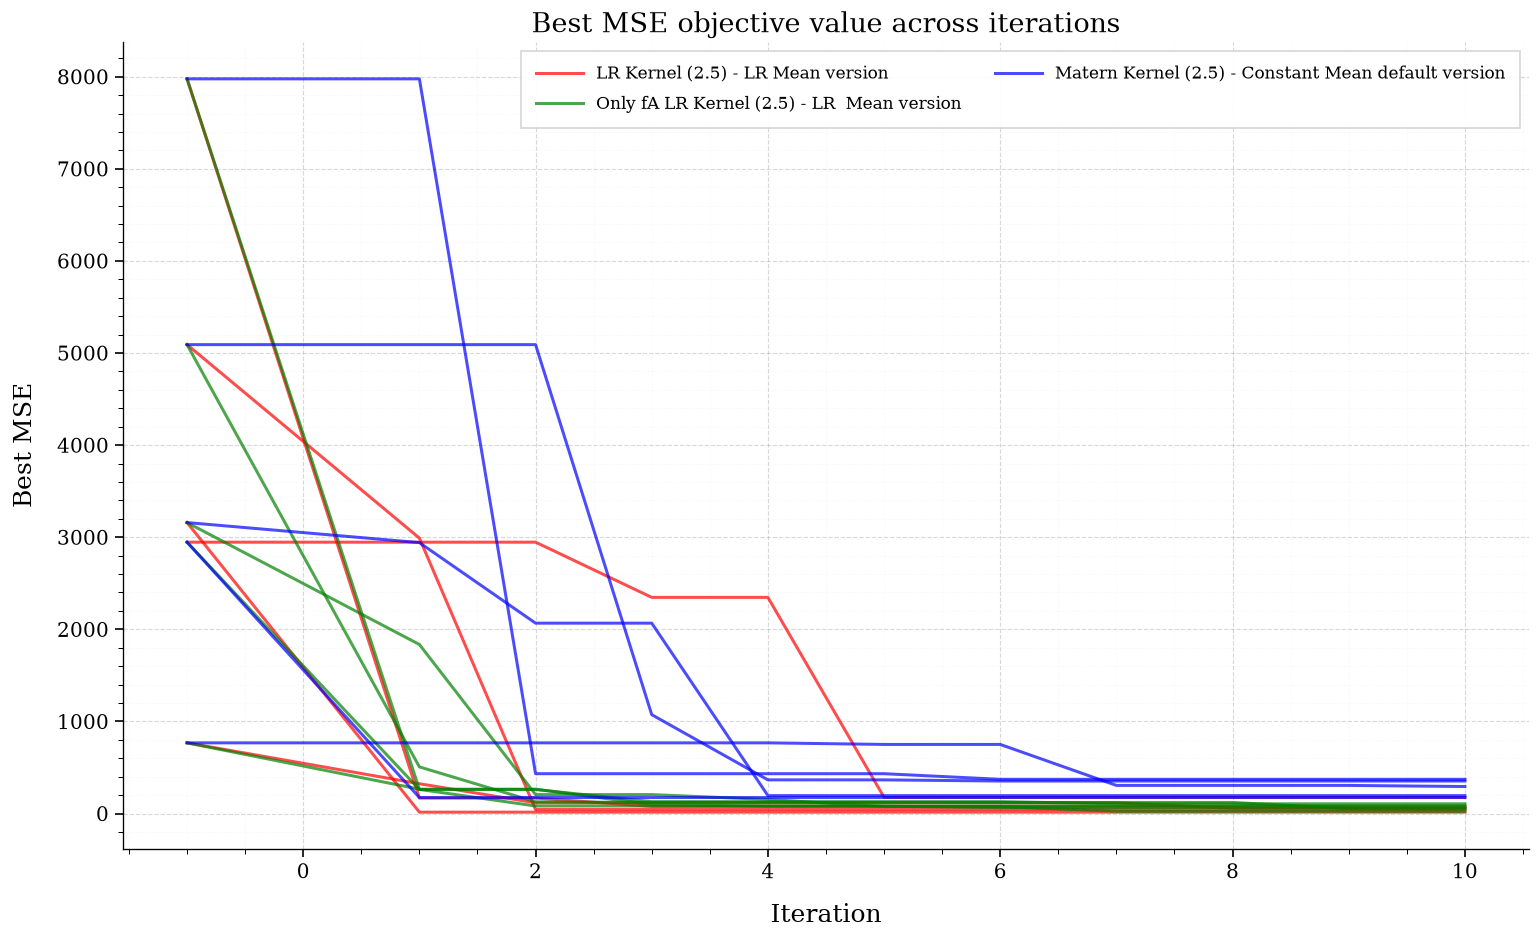

In [30]:
plt.figure(figsize=(13, 8), dpi=120)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_restart",
            #"outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_second_is_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_restart",
            #"outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_restart",
            #"outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    #"Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    #"LR Kernel (2.5) - Constant Mean version",
    #"Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]

colors = {
    "LR Kernel (2.5) - LR Mean version": "red",
    "Matern Kernel (2.5) - LR Mean version": "#E76F51",
    "Only fA LR Kernel (2.5) - LR  Mean version": "green",
    "LR Kernel (2.5) - Constant Mean version": "#E9C46A",
    "Only fA LR Kernel (2.5) - Constant Mean version": "#7B2CBF",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
}

# Styles différents pour améliorer la distinction visuelle
linestyles = {
    "LR Kernel (2.5) - LR Mean version": "-",
    "Matern Kernel (2.5) - LR Mean version": "-",
    "Only fA LR Kernel (2.5) - LR  Mean version": "-",
    "LR Kernel (2.5) - Constant Mean version": "--",
    "Only fA LR Kernel (2.5) - Constant Mean version": "--",
    "Matern Kernel (2.5) - Constant Mean default version": "-"
}



# Combined mean + kernel

def GP_plot(path,method_name):
    for rs in range(5):
        df = pd.read_csv(
            f'{path}{rs}.csv'
        )
        best_lost_df = df.groupby("iter").agg(
            {"loss_estimate": "min"}
        ).reset_index().rename(columns={"loss_estimate": "min_loss"})
        best_lost_df["min_loss"] = best_lost_df["min_loss"].cummin()

        plt.plot(
            best_lost_df.iter, best_lost_df.min_loss,
            label=method_name if rs == 0 else None,
            linewidth=1.8,
            alpha=0.7,
            color=colors[method_name],
            linestyle=linestyles["Only fA LR Kernel (2.5) - LR  Mean version"]
        )

for path,method_name in zip(paths_list,versions_list):
    GP_plot(path,method_name)

# Axes
plt.xlabel("Iteration", labelpad=12)
plt.ylabel("Best MSE", labelpad=12)

# Grid
plt.grid(
    True,
    which="major",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
    color="gray"
)

plt.minorticks_on()
plt.grid(
    True,
    which="minor",
    linestyle=":",
    linewidth=0.4,
    alpha=0.15
)

# Ticks
plt.tick_params(
    axis="both",
    which="major",
    direction="out",
    length=5,
    width=1
)

plt.tick_params(
    axis="both",
    which="minor",
    direction="out",
    length=3
)

# Legend
plt.legend(
    loc="upper right",
    ncol=2,
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    edgecolor="lightgray",
    borderpad=0.9,
    labelspacing=0.8,
    handlelength=2.8
)

plt.title("Best MSE objective value across iterations")

plt.tight_layout()
plt.show()

In [31]:
fA_function.coeffs

(-6.40621988,
 85.7352254,
 -7.41941697,
 11.0365529,
 0.186797158,
 0.404908884,
 -0.000279010501,
 -12.0503437)

# New initial sample

In [10]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

*** g_all:  [33, 42, 33, 42, 33, 51, 33, 42, 33, 42, 33, 42, 33, 18]
Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [ ]:
init_sample_x_norm = []
init_sample_y = []
init_df = []
for j1 in range(NUM_RESTARTS):
    train_X_norm, train_Y, df_init = initial_sampler.get_initial_sample(INIT_SAMPLE_SIZE, X_DIM ,bounds,error_function)
    init_sample_x_norm.append(train_X_norm)
    init_sample_y.append(train_Y)
    init_df.append(df_init)

torch.save(init_sample_x_norm,"./init_samples/second_init_sample_x_norm_route_error_route_file.pt")
torch.save(init_sample_y,"./init_samples/second_init_sample_y_route_error_route_file.pt")
torch.save(init_df,"./init_samples/second_init_df_route_error_route_file.pt")

# Linear Regression Kernel ConstantMean Mean

In [53]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [54]:
init_sample_x_norm=torch.load("./init_samples/second_init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/second_init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/second_init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [55]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["ConstantMean"],annotation="nu_2.5_route_error_route_file_second_is_original")

# Only fA Linear Regression Kernel ConstantMean Mean

In [32]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [33]:
init_sample_x_norm=torch.load("./init_samples/second_init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/second_init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/second_init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [34]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["ConstantMean"],annotation="nu_2.5_route_error_route_file_second_is_original")

# Linear Regression Kernel Linear Regression Mean

In [37]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [38]:
init_sample_x_norm=torch.load("./init_samples/second_init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/second_init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/second_init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [39]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["linear_regression"],annotation="nu_2.5_route_error_route_file_second_is_original")

# Matern Kernel default Linear Regression Mean

In [41]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [42]:
init_sample_x_norm=torch.load("./init_samples/second_init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/second_init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/second_init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [43]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["linear_regression"],annotation="nu_2.5_route_error_route_file_second_is_original")

# Only fA Linear regression Kernel Linear Regression Mean

In [45]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [46]:
init_sample_x_norm=torch.load("./init_samples/second_init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/second_init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/second_init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [47]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["linear_regression"],annotation="nu_2.5_route_error_route_file_second_is_original")

# Default version

In [49]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [50]:
init_sample_x_norm=torch.load("./init_samples/second_init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/second_init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/second_init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [51]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["ConstantMean"],annotation="nu_2.5_route_error_route_file_second_is_original")

# Comparison of all methods

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,1494.940543,1408.848062
1,1.0,292.724283,163.755270
2,2.0,218.950448,47.578620
3,3.0,181.066664,62.782973
4,4.0,169.511357,56.064932
5,5.0,143.655382,72.888798
6,6.0,122.644714,55.694162
7,7.0,122.644714,55.694162
8,8.0,122.644714,55.694162
9,9.0,122.644714,55.694162


agg df for Matern Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,1494.940543,1408.848062
1,1.0,891.250677,1163.168057
2,2.0,344.966392,149.326626
3,3.0,344.966392,149.326626
4,4.0,344.966392,149.326626
5,5.0,309.990032,181.683554
6,6.0,301.995865,185.013325
7,7.0,301.995865,185.013325
8,8.0,301.995865,185.013325
9,9.0,301.995865,185.013325


agg df for Only fA LR Kernel (2.5) - LR  Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,1494.940543,1408.848062
1,1.0,1172.643015,1535.231055
2,2.0,905.032536,1633.486918
3,3.0,898.272861,1637.018291
4,4.0,890.548424,1640.807786
5,5.0,185.181417,92.085462
6,6.0,163.629630,68.308634
7,7.0,163.629630,68.308634
8,8.0,157.759435,62.922362
9,9.0,143.445788,59.844557


... (2 outputs left out)

agg df for Only fA LR Kernel (2.5) - Constant Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,1494.940543,1408.848062
1,1.0,1210.787517,1514.034938
2,2.0,1157.752121,1546.241074
3,3.0,1157.752121,1546.241074
4,4.0,1157.752121,1546.241074
5,5.0,1157.752121,1546.241074
6,6.0,1157.752121,1546.241074
7,7.0,1106.319192,1435.743405
8,8.0,1106.319192,1435.743405
9,9.0,1106.319192,1435.743405


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,1494.940543,1408.848062
1,1.0,642.846208,548.311556
2,2.0,642.846208,548.311556
3,3.0,623.689454,555.765052
4,4.0,335.978952,157.240650
5,5.0,335.978952,157.240650
6,6.0,332.005504,149.813344
7,7.0,324.045419,144.804718
8,8.0,289.535287,101.618538
9,9.0,252.778112,75.128806


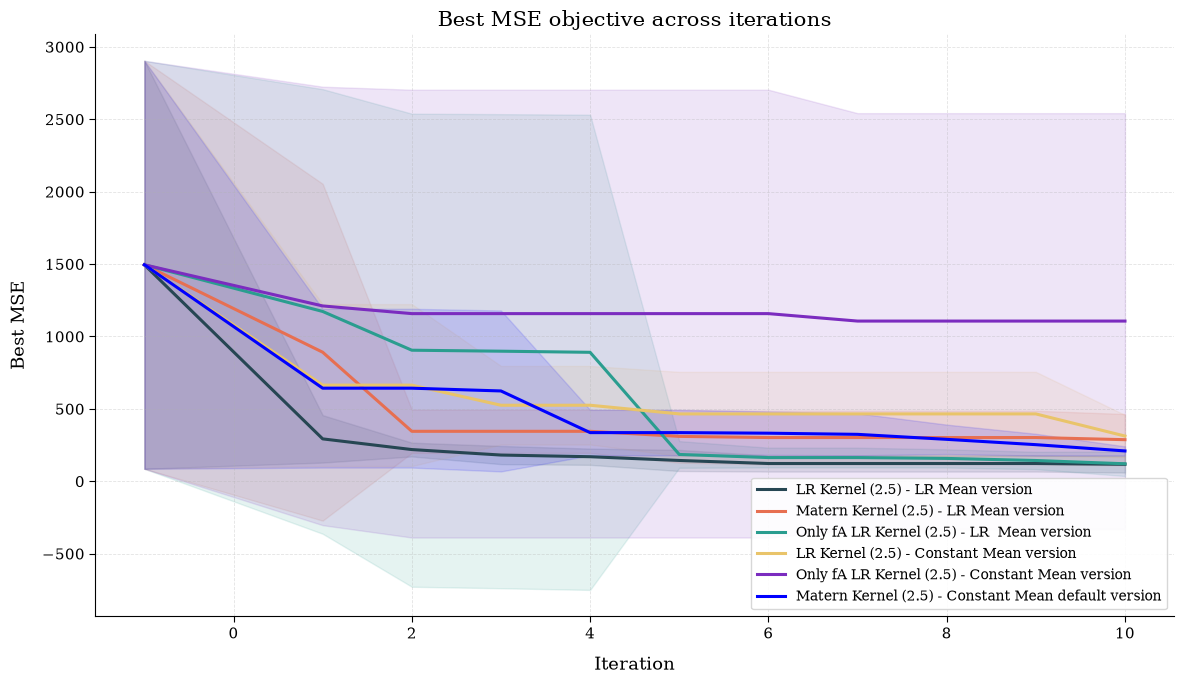

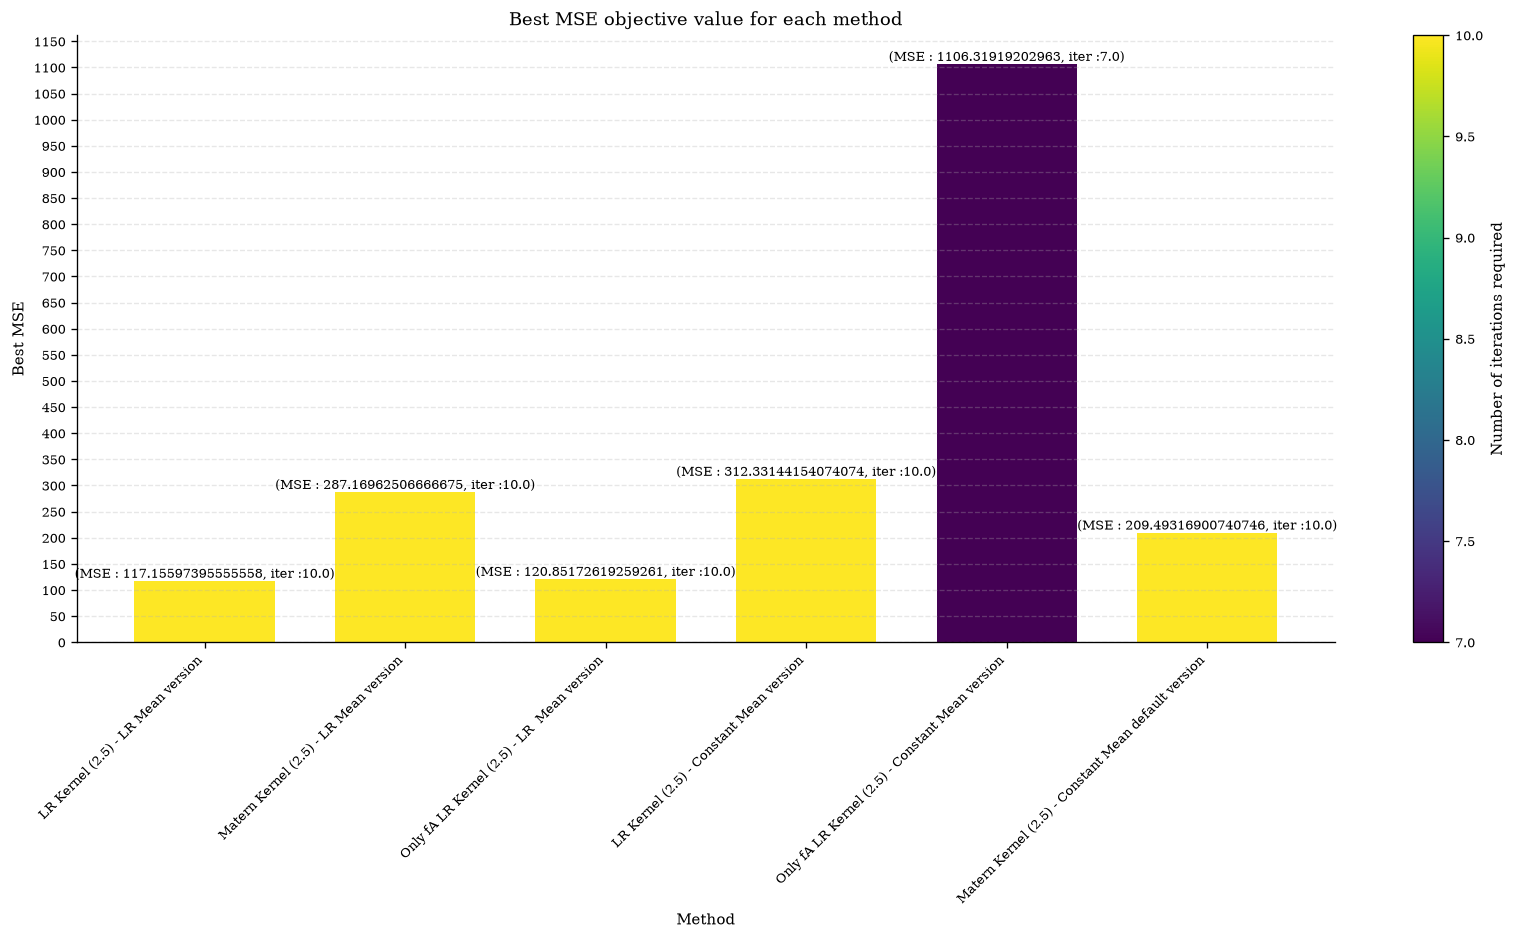

In [57]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - LR Mean version": "#E76F51",
    "Only fA LR Kernel (2.5) - LR  Mean version": "#2A9D8F",
    "LR Kernel (2.5) - Constant Mean version": "#E9C46A",
    "Only fA LR Kernel (2.5) - Constant Mean version": "#7B2CBF",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(5):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_second_is_original_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - LR Mean version":0,
        "Only fA LR Kernel (2.5) - LR  Mean version":0,
        "LR Kernel (2.5) - Constant Mean version":0,
        "Only fA LR Kernel (2.5) - Constant Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

for bar, iteration, min_value in zip(bars, iterations, min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value}, iter :{iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Number of iterations required", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

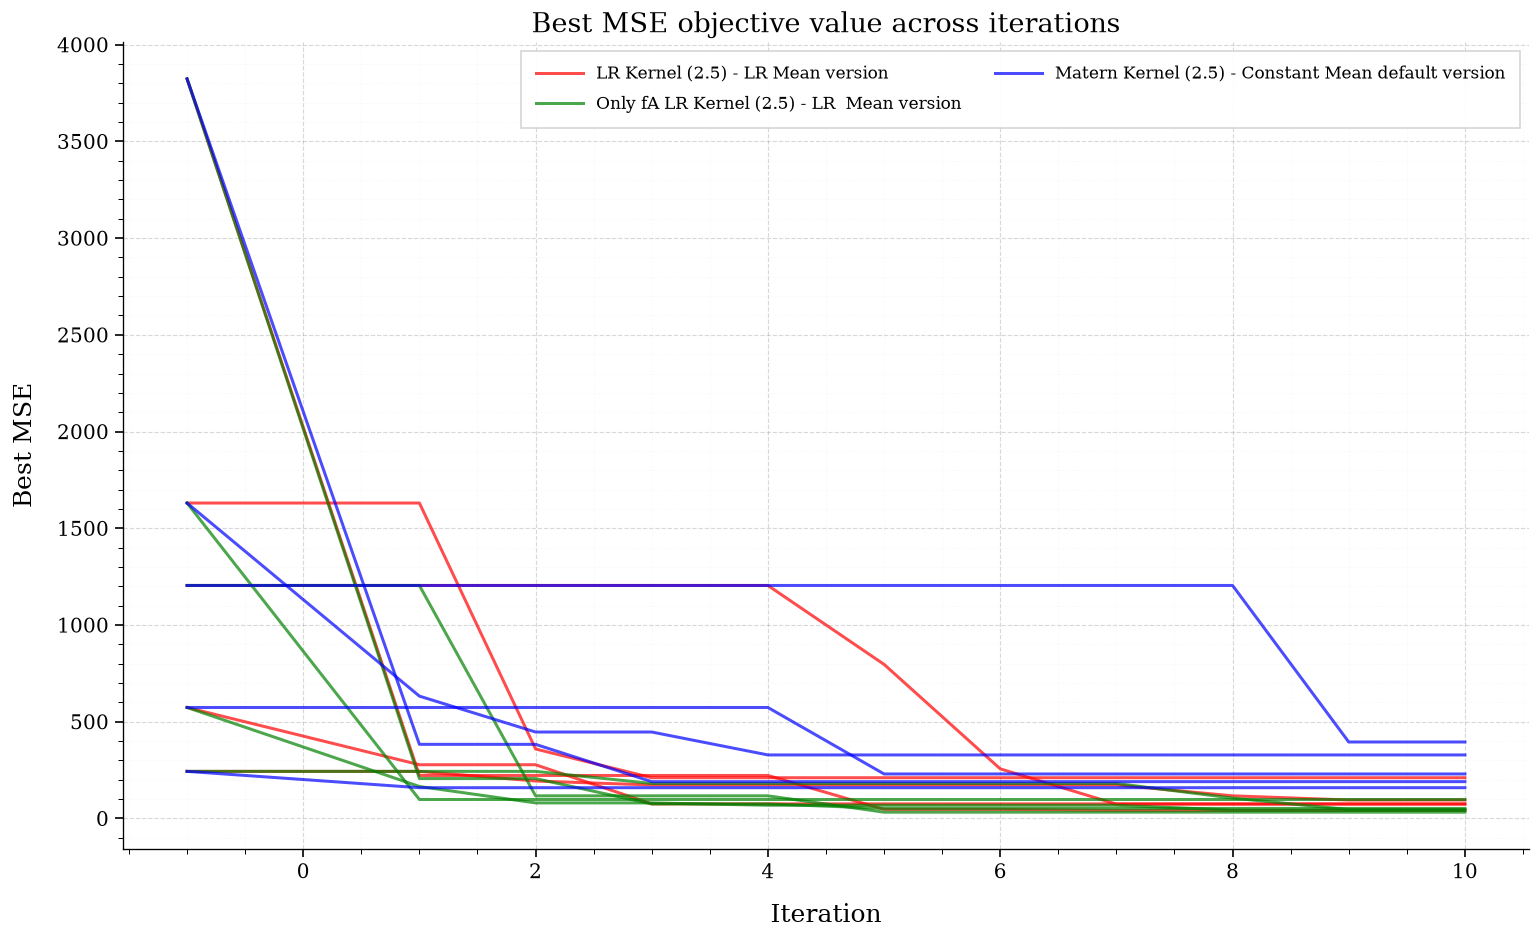

In [59]:
plt.figure(figsize=(13, 8), dpi=120)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_second_is_restart",
            #"outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_second_is_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_second_is_restart",
            #"outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_restart",
            #"outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_second_is_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    #"Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    #"LR Kernel (2.5) - Constant Mean version",
    #"Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]

colors = {
    "LR Kernel (2.5) - LR Mean version": "red",
    "Matern Kernel (2.5) - LR Mean version": "#E76F51",
    "Only fA LR Kernel (2.5) - LR  Mean version": "green",
    "LR Kernel (2.5) - Constant Mean version": "#E9C46A",
    "Only fA LR Kernel (2.5) - Constant Mean version": "#7B2CBF",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
}

# Styles différents pour améliorer la distinction visuelle
linestyles = {
    "LR Kernel (2.5) - LR Mean version": "-",
    "Matern Kernel (2.5) - LR Mean version": "-",
    "Only fA LR Kernel (2.5) - LR  Mean version": "-",
    "LR Kernel (2.5) - Constant Mean version": "--",
    "Only fA LR Kernel (2.5) - Constant Mean version": "--",
    "Matern Kernel (2.5) - Constant Mean default version": "-"
}



# Combined mean + kernel

def GP_plot(path,method_name):
    for rs in range(5):
        df = pd.read_csv(
            f'{path}{rs}.csv'
        )
        best_lost_df = df.groupby("iter").agg(
            {"loss_estimate": "min"}
        ).reset_index().rename(columns={"loss_estimate": "min_loss"})
        best_lost_df["min_loss"] = best_lost_df["min_loss"].cummin()

        plt.plot(
            best_lost_df.iter, best_lost_df.min_loss,
            label=method_name if rs == 0 else None,
            linewidth=1.8,
            alpha=0.7,
            color=colors[method_name],
            linestyle=linestyles["Only fA LR Kernel (2.5) - LR  Mean version"]
        )

for path,method_name in zip(paths_list,versions_list):
    GP_plot(path,method_name)

# Axes
plt.xlabel("Iteration", labelpad=12)
plt.ylabel("Best MSE", labelpad=12)

# Grid
plt.grid(
    True,
    which="major",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
    color="gray"
)

plt.minorticks_on()
plt.grid(
    True,
    which="minor",
    linestyle=":",
    linewidth=0.4,
    alpha=0.15
)

# Ticks
plt.tick_params(
    axis="both",
    which="major",
    direction="out",
    length=5,
    width=1
)

plt.tick_params(
    axis="both",
    which="minor",
    direction="out",
    length=3
)

# Legend
plt.legend(
    loc="upper right",
    ncol=2,
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    edgecolor="lightgray",
    borderpad=0.9,
    labelspacing=0.8,
    handlelength=2.8
)

plt.title("Best MSE objective value across iterations")

plt.tight_layout()
plt.show()

# Try with different level of congestion for the Ground Truth DF

In [ ]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML_GT = "ingolstadt7/additional.gt_scenario.xml"
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set

TL_IDS_SET = get_tls()

low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                    [up_bound]*(X_DIM-1)+[50]], 
                    device=device, dtype=dtype)


sumo_runner_gt=SumoRun(
    add_xml=ADD_XML_GT,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)


g_dict_to_vary={
            "gneJ260":"GGGGGgrrr",
            "gneJ210": "GGggrrrrrrGGGG",
            "32564122": "GGGGGgrrr",
            "gneJ207":"GGgGrGGG",
            "gneJ143": "rrrGGGGgGGGg",
            "cluster_1757124350_1757124352":"GGgrrGGG",
            "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
        }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}



connexions_green_time_creator=ConnexionsGreenTime(
        tl_ids=TL_IDS_SET,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        net_xml=net_xml,
        g_dict_to_change=g_dict_to_change,
        g_dict_to_vary=g_dict_to_vary,
        g_dict_const=g_dict_const,
        dtype=dtype
    )


optimizer=Optimization(batch_size=BATCH_SIZE,
                        num_restarts=NUM_RESTARTS,
                        device=device,
                        dtype=dtype,
                        raw_samples=RAW_SAMPLES)



g1_values=[15,20,25,30]
g2_values=[20,25,30,35]

for g1,g2 in zip(g1_values,g2_values):

    g_vec_gt=np.array([g1]*7)
    g_vec_gt[2]=g2

    sumo_runner_gt.sumo_run_parse_data(g_vec_gt, epoch_indx=f"gt_route_file_g1_{g1}_g2_{g2}")

    DF_GT = pd.read_csv(f'./gt_data/gt_route_file_g1_{g1}_g2_{g2}_travel_times.csv')
    DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

    error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)
    init_sample_x_norm = []
    init_sample_y = []
    init_df = []
    for j1 in range(NUM_RESTARTS):
        x_sample, y_sample, df_init = initial_sampler.get_initial_sample(INIT_SAMPLE_SIZE, X_DIM ,bounds,error_function)
        init_sample_x_norm.append(x_sample)
        init_sample_y.append(y_sample)
        init_df.append(df_init)

    torch.save(init_sample_x_norm,f"./init_samples/init_sample_x_norm_route_error_route_file_g1_{g1}_g2_{g2}.pt")
    torch.save(init_sample_y,f"./init_samples/init_sample_y_route_error_route_file_g1_{g1}_g2_{g2}.pt")
    torch.save(init_df,f"./init_samples/init_df_route_error_route_file_g1_{g1}_g2_{g2}.pt")



    init_sample_x_norm=torch.load(f"./init_samples/init_sample_x_norm_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)
    init_sample_y=torch.load(f"./init_samples/init_sample_y_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)
    init_df=torch.load(f"./init_samples/init_df_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)

    tl_ids=TL_IDS_SET
    df_gt=DF_GT
    

    fA_function=UpdatedFAFunctionLinearRegresion(
        df_gt=DF_GT,
        corridors_df=corridors_df,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        connexions_green_time_extractor=connexions_green_time_creator,
        dtype=dtype,
        connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
    )


    gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
    )


    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df,
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)

    bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_g1_{g1}_g2_{g2}_original")


In [ ]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML_GT = "ingolstadt7/additional.gt_scenario.xml"
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set

TL_IDS_SET = get_tls()

low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                    [up_bound]*(X_DIM-1)+[50]], 
                    device=device, dtype=dtype)


sumo_runner_gt=SumoRun(
    add_xml=ADD_XML_GT,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)


g_dict_to_vary={
            "gneJ260":"GGGGGgrrr",
            "gneJ210": "GGggrrrrrrGGGG",
            "32564122": "GGGGGgrrr",
            "gneJ207":"GGgGrGGG",
            "gneJ143": "rrrGGGGgGGGg",
            "cluster_1757124350_1757124352":"GGgrrGGG",
            "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
        }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}



connexions_green_time_creator=ConnexionsGreenTime(
        tl_ids=TL_IDS_SET,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        net_xml=net_xml,
        g_dict_to_change=g_dict_to_change,
        g_dict_to_vary=g_dict_to_vary,
        g_dict_const=g_dict_const,
        dtype=dtype
    )


optimizer=Optimization(batch_size=BATCH_SIZE,
                        num_restarts=NUM_RESTARTS,
                        device=device,
                        dtype=dtype,
                        raw_samples=RAW_SAMPLES)



g1_values=[15,20,25,30]
g2_values=[20,25,30,35]

for g1,g2 in zip(g1_values,g2_values):


    DF_GT = pd.read_csv(f'./gt_data/gt_route_file_g1_{g1}_g2_{g2}_travel_times.csv')
    DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

    error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)



    init_sample_x_norm=torch.load(f"./init_samples/init_sample_x_norm_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)
    init_sample_y=torch.load(f"./init_samples/init_sample_y_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)
    init_df=torch.load(f"./init_samples/init_df_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)

    tl_ids=TL_IDS_SET
    df_gt=DF_GT
    

    fA_function=UpdatedFAFunctionLinearRegresion(
        df_gt=DF_GT,
        corridors_df=corridors_df,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        connexions_green_time_extractor=connexions_green_time_creator,
        dtype=dtype,
        connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
    )


    gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
    )


    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df,
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)

    bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["ConstantMean"],annotation=f"nu_2.5_route_error_route_file_g1_{g1}_g2_{g2}_original")


In [ ]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML_GT = "ingolstadt7/additional.gt_scenario.xml"
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set

TL_IDS_SET = get_tls()

low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                    [up_bound]*(X_DIM-1)+[50]], 
                    device=device, dtype=dtype)


sumo_runner_gt=SumoRun(
    add_xml=ADD_XML_GT,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)


g_dict_to_vary={
            "gneJ260":"GGGGGgrrr",
            "gneJ210": "GGggrrrrrrGGGG",
            "32564122": "GGGGGgrrr",
            "gneJ207":"GGgGrGGG",
            "gneJ143": "rrrGGGGgGGGg",
            "cluster_1757124350_1757124352":"GGgrrGGG",
            "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
        }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}



connexions_green_time_creator=ConnexionsGreenTime(
        tl_ids=TL_IDS_SET,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        net_xml=net_xml,
        g_dict_to_change=g_dict_to_change,
        g_dict_to_vary=g_dict_to_vary,
        g_dict_const=g_dict_const,
        dtype=dtype
    )


optimizer=Optimization(batch_size=BATCH_SIZE,
                        num_restarts=NUM_RESTARTS,
                        device=device,
                        dtype=dtype,
                        raw_samples=RAW_SAMPLES)



g1_values=[15,20,25,30]
g2_values=[20,25,30,35]

for g1,g2 in zip(g1_values,g2_values):


    DF_GT = pd.read_csv(f'./gt_data/gt_route_file_g1_{g1}_g2_{g2}_travel_times.csv')
    DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

    error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)



    init_sample_x_norm=torch.load(f"./init_samples/init_sample_x_norm_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)
    init_sample_y=torch.load(f"./init_samples/init_sample_y_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)
    init_df=torch.load(f"./init_samples/init_df_route_error_route_file_g1_{g1}_g2_{g2}.pt",weights_only=False)

    tl_ids=TL_IDS_SET
    df_gt=DF_GT
    

    fA_function=UpdatedFAFunctionLinearRegresion(
        df_gt=DF_GT,
        corridors_df=corridors_df,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        connexions_green_time_extractor=connexions_green_time_creator,
        dtype=dtype,
        connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
    )


    gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
    )


    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df,
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)

    bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_g1_{g1}_g2_{g2}_original")


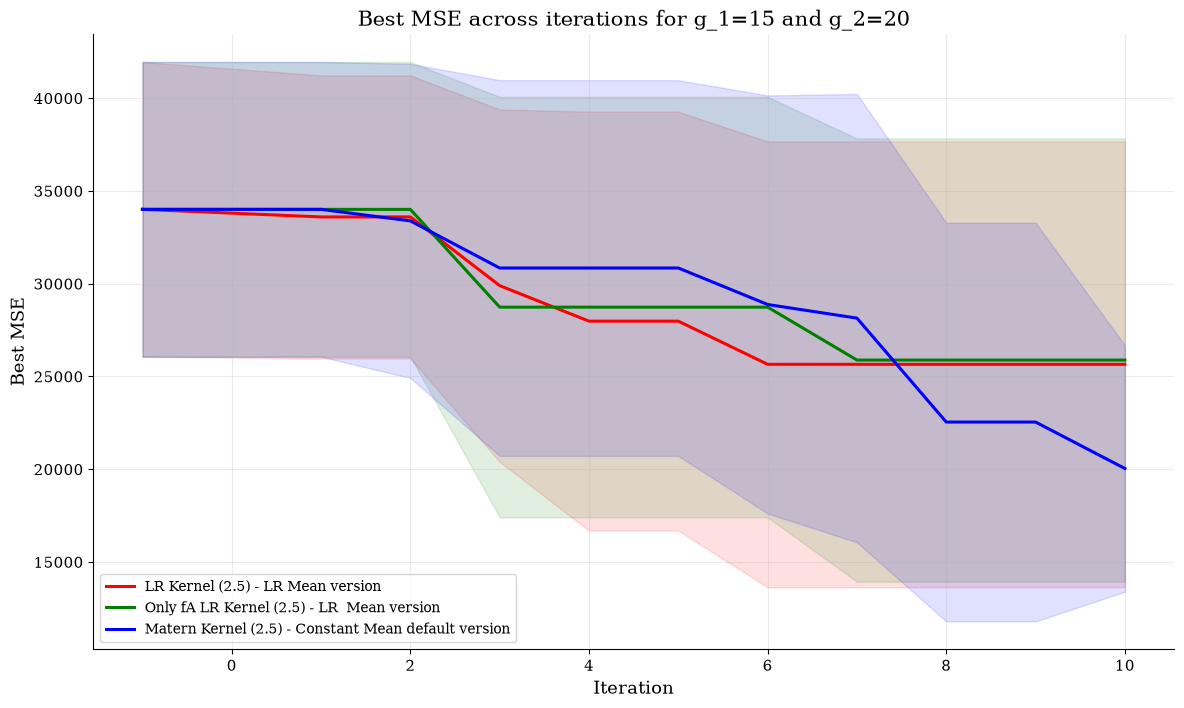

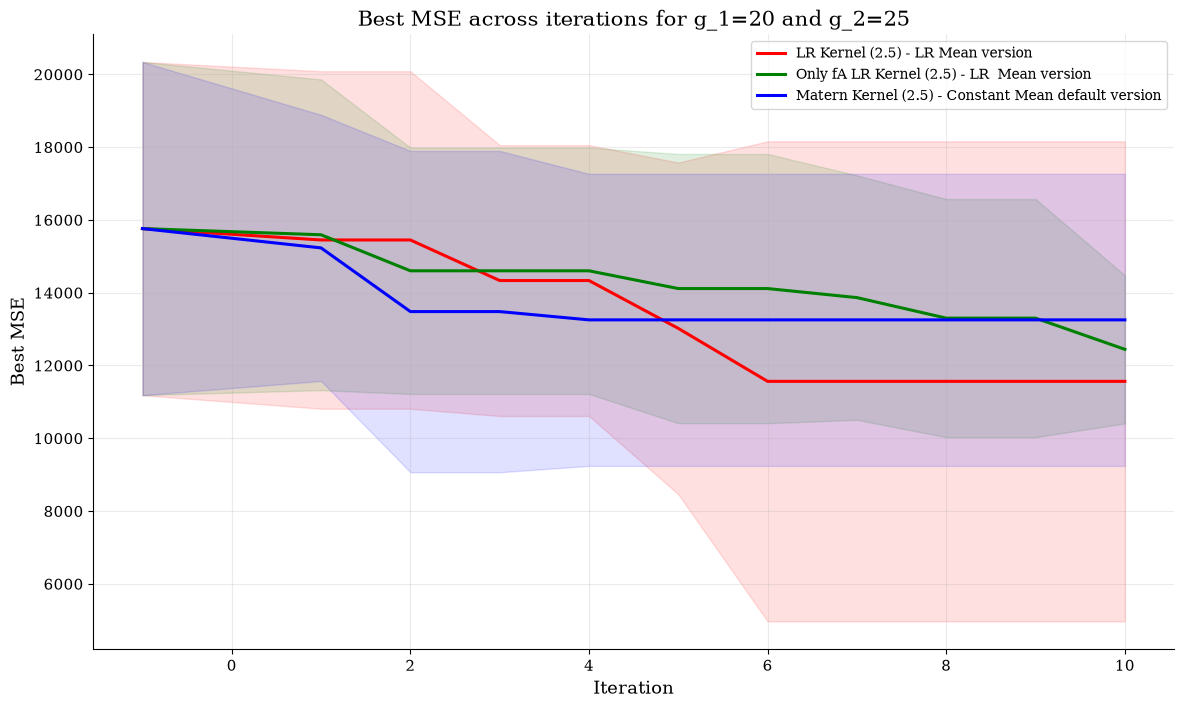

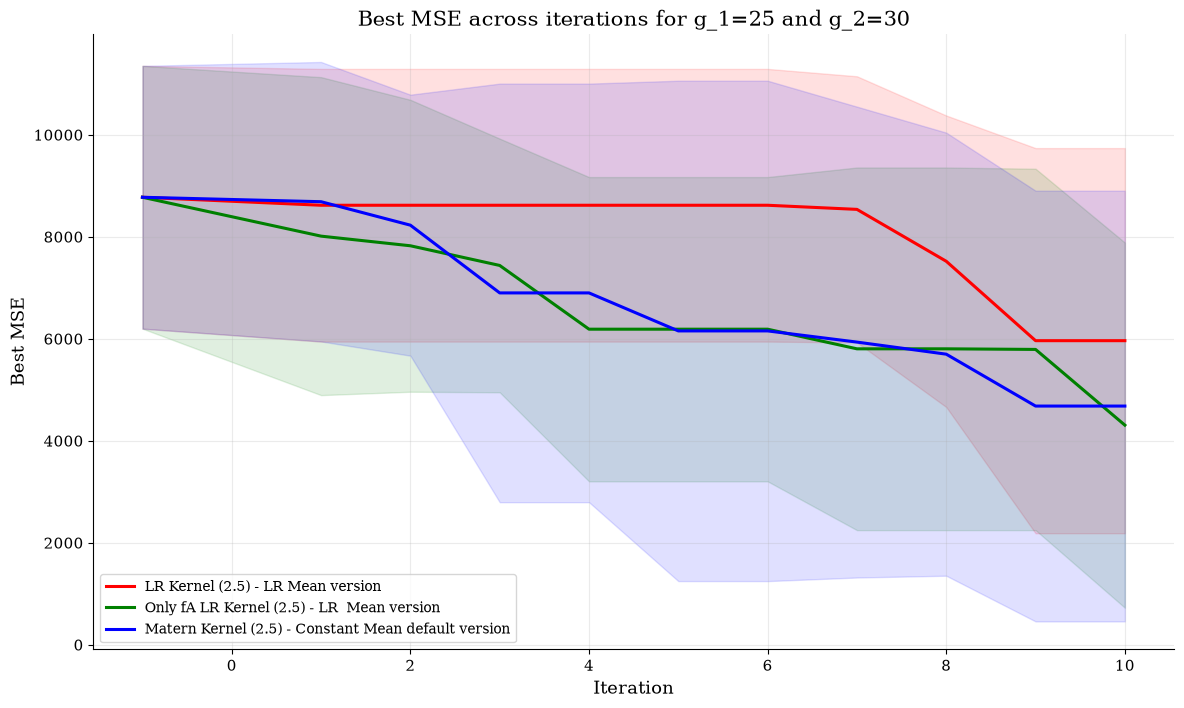

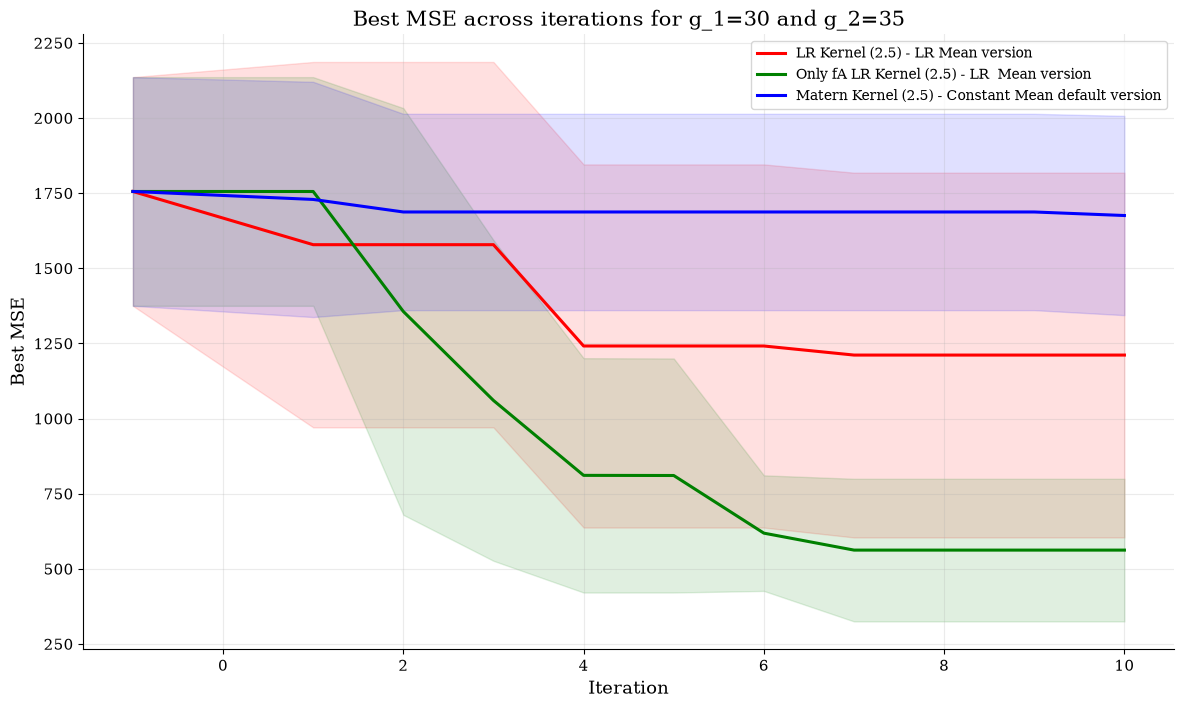

In [31]:

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file"]

colors_dict={
    "LR Kernel (2.5) - LR Mean version":"red",
    "Only fA LR Kernel (2.5) - LR  Mean version":"green",
    "Matern Kernel (2.5) - Constant Mean default version":"blue"
}

def GP_plot(path,method_name,colors_dict):
    
    best_df_all_mean=None
    for rs in range(5):
        df = pd.read_csv(f"{path}_restart{rs}.csv")
        best_lost_df = df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"] = best_lost_df["min_loss"].cummin()
        if best_df_all_mean is None:
            best_df_all_mean = best_lost_df
        else:
            best_df_all_mean = pd.concat([best_df_all_mean, best_lost_df], axis=0)

    agg_best_df_all_mean = best_df_all_mean.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})


    plt.plot(
            agg_best_df_all_mean.iter,
            agg_best_df_all_mean.best_loss_mean,
            linewidth=2.2,
            color=colors_dict[method_name],
            label=method_name
        )
    
    plt.fill_between(
        agg_best_df_all_mean.iter,
        agg_best_df_all_mean.best_loss_mean - agg_best_df_all_mean.best_loss_std,
        agg_best_df_all_mean.best_loss_mean + agg_best_df_all_mean.best_loss_std,
        color=colors_dict[method_name],
        alpha=0.12
        )
        
g1_values = [15, 20, 25, 30]
g2_values = [20, 25, 30, 35]
for (g1, g2)in zip(g1_values, g2_values):
    plt.figure(figsize=(12, 7))
    for path,method_name in zip(paths_list,versions_list):
        path=path+f"_g1_{g1}_g2_{g2}_original"
        GP_plot(path,method_name,colors_dict=colors_dict)


    plt.xlabel("Iteration")
    plt.ylabel("Best MSE")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.title(f"Best MSE across iterations for g_1={g1} and g_2={g2}")

# Try with different level of demand

In [ ]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML_GT = "ingolstadt7/additional.gt_scenario.xml"
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set

TL_IDS_SET = get_tls()

low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                    [up_bound]*(X_DIM-1)+[50]], 
                    device=device, dtype=dtype)


sumo_runner_gt=SumoRun(
    add_xml=ADD_XML_GT,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

BATCH_SIZE = 1
NUM_RESTARTS = 3
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3
NUM_RESTARTS_OPTI=5

initial_sampler=InitialSamples(
    dtype=dtype
)

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)


g_dict_to_vary={
            "gneJ260":"GGGGGgrrr",
            "gneJ210": "GGggrrrrrrGGGG",
            "32564122": "GGGGGgrrr",
            "gneJ207":"GGgGrGGG",
            "gneJ143": "rrrGGGGgGGGg",
            "cluster_1757124350_1757124352":"GGgrrGGG",
            "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
        }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}



connexions_green_time_creator=ConnexionsGreenTime(
        tl_ids=TL_IDS_SET,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        net_xml=net_xml,
        g_dict_to_change=g_dict_to_change,
        g_dict_to_vary=g_dict_to_vary,
        g_dict_const=g_dict_const,
        dtype=dtype
    )


optimizer=Optimization(batch_size=BATCH_SIZE,
                        num_restarts=NUM_RESTARTS_OPTI,
                        device=device,
                        dtype=dtype,
                        raw_samples=RAW_SAMPLES)


g_vec_gt=np.array([38,38,42,38,38,38,36])
scaling_demand_factors_list=[0.5,0.75,1.25,1.75,2]
for scaling_demand_factor in scaling_demand_factors_list:

    sumo_runner_gt.sumo_run_parse_data(g_vec_gt, epoch_indx=f"gt_route_file_sdf_{scaling_demand_factor}",scaling_demand_factor=scaling_demand_factor)

    DF_GT = pd.read_csv(f'./gt_data/gt_route_file_sdf_{scaling_demand_factor}_travel_times.csv')
    DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

    error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)
    init_sample_x_norm = []
    init_sample_y = []
    init_df = []
    for j1 in range(NUM_RESTARTS):
        x_sample, y_sample, df_init = initial_sampler.get_initial_sample(INIT_SAMPLE_SIZE, X_DIM ,bounds,error_function,scaling_demand_factor=scaling_demand_factor)
        init_sample_x_norm.append(x_sample)
        init_sample_y.append(y_sample)
        init_df.append(df_init)

    torch.save(init_sample_x_norm,f"./init_samples/init_sample_x_norm_route_error_route_file_sdf_{scaling_demand_factor}.pt")
    torch.save(init_sample_y,f"./init_samples/init_sample_y_route_error_route_file_sdf_{scaling_demand_factor}.pt")
    torch.save(init_df,f"./init_samples/init_df_route_error_route_file_sdf_{scaling_demand_factor}.pt")



    init_sample_x_norm=torch.load(f"./init_samples/init_sample_x_norm_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)
    init_sample_y=torch.load(f"./init_samples/init_sample_y_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)
    init_df=torch.load(f"./init_samples/init_df_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)

    tl_ids=TL_IDS_SET
    df_gt=DF_GT
    

    fA_function=UpdatedFAFunctionLinearRegresion(
        df_gt=DF_GT,
        corridors_df=corridors_df,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        connexions_green_time_extractor=connexions_green_time_creator,
        dtype=dtype,
        connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
    )


    gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
    )

    for init_sample in range(3):
        bo_loop=BOLoop(niter=NITER,
                    num_restart=NUM_RESTARTS,
                    init_df=init_df[init_sample],
                    gp_initializer=gp_initializer,
                    error_function=error_function,
                    optimizer=optimizer,
                    dtype=dtype,
                    x_dim=X_DIM,
                    loss_scale=SCALING_FACTOR_LOSS_FN,
                    sample_size=INIT_SAMPLE_SIZE,
                    output_dir=OUTPUT_DIR,
                    bounds=bounds)
        bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_sdf_{scaling_demand_factor}_is{init_sample}",scaling_demand_factor=scaling_demand_factor)


In [ ]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML_GT = "ingolstadt7/additional.gt_scenario.xml"
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set

TL_IDS_SET = get_tls()

low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                    [up_bound]*(X_DIM-1)+[50]], 
                    device=device, dtype=dtype)


sumo_runner_gt=SumoRun(
    add_xml=ADD_XML_GT,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

BATCH_SIZE = 1
NUM_RESTARTS = 3
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3
NUM_RESTARTS_OPTI=5

initial_sampler=InitialSamples(
    dtype=dtype
)

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)


g_dict_to_vary={
            "gneJ260":"GGGGGgrrr",
            "gneJ210": "GGggrrrrrrGGGG",
            "32564122": "GGGGGgrrr",
            "gneJ207":"GGgGrGGG",
            "gneJ143": "rrrGGGGgGGGg",
            "cluster_1757124350_1757124352":"GGgrrGGG",
            "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
        }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}



connexions_green_time_creator=ConnexionsGreenTime(
        tl_ids=TL_IDS_SET,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        net_xml=net_xml,
        g_dict_to_change=g_dict_to_change,
        g_dict_to_vary=g_dict_to_vary,
        g_dict_const=g_dict_const,
        dtype=dtype
    )


optimizer=Optimization(batch_size=BATCH_SIZE,
                        num_restarts=NUM_RESTARTS_OPTI,
                        device=device,
                        dtype=dtype,
                        raw_samples=RAW_SAMPLES)


g_vec_gt=np.array([38,38,42,38,38,38,36])
scaling_demand_factors_list=[0.5,0.75,1.25,1.75,2]
for scaling_demand_factor in scaling_demand_factors_list:

    DF_GT = pd.read_csv(f'./gt_data/gt_route_file_sdf_{scaling_demand_factor}_travel_times.csv')
    DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

    error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)



    init_sample_x_norm=torch.load(f"./init_samples/init_sample_x_norm_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)
    init_sample_y=torch.load(f"./init_samples/init_sample_y_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)
    init_df=torch.load(f"./init_samples/init_df_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)

    tl_ids=TL_IDS_SET
    df_gt=DF_GT
    

    fA_function=UpdatedFAFunctionLinearRegresion(
        df_gt=DF_GT,
        corridors_df=corridors_df,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        connexions_green_time_extractor=connexions_green_time_creator,
        dtype=dtype,
        connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
    )


    gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
    )

    for init_sample in range(3):
        bo_loop=BOLoop(niter=NITER,
                    num_restart=NUM_RESTARTS,
                    init_df=init_df[init_sample],
                    gp_initializer=gp_initializer,
                    error_function=error_function,
                    optimizer=optimizer,
                    dtype=dtype,
                    x_dim=X_DIM,
                    loss_scale=SCALING_FACTOR_LOSS_FN,
                    sample_size=INIT_SAMPLE_SIZE,
                    output_dir=OUTPUT_DIR,
                    bounds=bounds)
        bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_sdf_{scaling_demand_factor}_is{init_sample}",scaling_demand_factor=scaling_demand_factor)


In [ ]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML_GT = "ingolstadt7/additional.gt_scenario.xml"
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1

def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set

TL_IDS_SET = get_tls()

low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                    [up_bound]*(X_DIM-1)+[50]], 
                    device=device, dtype=dtype)


sumo_runner_gt=SumoRun(
    add_xml=ADD_XML_GT,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

BATCH_SIZE = 1
NUM_RESTARTS = 3
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3
NUM_RESTARTS_OPTI=5

initial_sampler=InitialSamples(
    dtype=dtype
)

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(route_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)


g_dict_to_vary={
            "gneJ260":"GGGGGgrrr",
            "gneJ210": "GGggrrrrrrGGGG",
            "32564122": "GGGGGgrrr",
            "gneJ207":"GGgGrGGG",
            "gneJ143": "rrrGGGGgGGGg",
            "cluster_1757124350_1757124352":"GGgrrGGG",
            "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
        }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}



connexions_green_time_creator=ConnexionsGreenTime(
        tl_ids=TL_IDS_SET,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        net_xml=net_xml,
        g_dict_to_change=g_dict_to_change,
        g_dict_to_vary=g_dict_to_vary,
        g_dict_const=g_dict_const,
        dtype=dtype
    )


optimizer=Optimization(batch_size=BATCH_SIZE,
                        num_restarts=NUM_RESTARTS_OPTI,
                        device=device,
                        dtype=dtype,
                        raw_samples=RAW_SAMPLES)


g_vec_gt=np.array([38,38,42,38,38,38,36])
scaling_demand_factors_list=[0.5,0.75,1.25,1.75,2]
for scaling_demand_factor in scaling_demand_factors_list:

    DF_GT = pd.read_csv(f'./gt_data/gt_route_file_sdf_{scaling_demand_factor}_travel_times.csv')
    DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

    error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)



    init_sample_x_norm=torch.load(f"./init_samples/init_sample_x_norm_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)
    init_sample_y=torch.load(f"./init_samples/init_sample_y_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)
    init_df=torch.load(f"./init_samples/init_df_route_error_route_file_sdf_{scaling_demand_factor}.pt",weights_only=False)

    tl_ids=TL_IDS_SET
    df_gt=DF_GT
    

    fA_function=UpdatedFAFunctionLinearRegresion(
        df_gt=DF_GT,
        corridors_df=corridors_df,
        complete_corridors_connexions_df=complete_corridors_connexions_df,
        connexions_green_time_extractor=connexions_green_time_creator,
        dtype=dtype,
        connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
    )


    gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
    )

    for init_sample in range(3):
        bo_loop=BOLoop(niter=NITER,
                    num_restart=NUM_RESTARTS,
                    init_df=init_df[init_sample],
                    gp_initializer=gp_initializer,
                    error_function=error_function,
                    optimizer=optimizer,
                    dtype=dtype,
                    x_dim=X_DIM,
                    loss_scale=SCALING_FACTOR_LOSS_FN,
                    sample_size=INIT_SAMPLE_SIZE,
                    output_dir=OUTPUT_DIR,
                    bounds=bounds)
        bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_sdf_{scaling_demand_factor}_is{init_sample}",scaling_demand_factor=scaling_demand_factor)


# CDF Curves

In [65]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)


Number of GT edges: 92


In [ ]:
def create_validation_df(first_path,second_path,method_name):

    validation_df=None
    for rs in range(5):
        df_1=pd.read_csv(f'{first_path}{rs}.csv')
        best_solution_index=np.argmin(df_1["loss_estimate"].values)
        best_solution=df_1[[f"g{i}" for i in range(7)]].iloc[best_solution_index].values
        for i in range(5):
            mse=error_function.compute_error(best_solution,epoch_indx=f"validation_{method_name}_first_is_original_rep{i}_rs{rs}")
            sub_validation_df=pd.DataFrame(np.append(np.hstack([best_solution,mse]),i).reshape(1,-1),columns=[f"g{g}" for g in range(7)]+["mse","rep"])
            
            if validation_df is None:
                validation_df=sub_validation_df
            else:
                validation_df=pd.concat([validation_df,sub_validation_df],axis=0,ignore_index=True)

        df_2=pd.read_csv(f'{second_path}{rs}.csv')
        best_solution_index=np.argmin(df_2["loss_estimate"].values)
        best_solution=df_2[[f"g{i}" for i in range(7)]].iloc[best_solution_index].values
        for i in range(5):
            mse=error_function.compute_error(best_solution,epoch_indx=f"validation_{method_name}_second_is_original_rep{i}_rs{rs}")
            sub_validation_df=pd.DataFrame(np.append(np.hstack([best_solution,mse]),i).reshape(1,-1),columns=[f"g{g}" for g in range(7)]+["mse","rep"])
            
            validation_df=pd.concat([validation_df,sub_validation_df],axis=0,ignore_index=True)

    validation_df["CDF"]=ecdf(validation_df["mse"].values).cdf.evaluate(validation_df["mse"])
    torch.save(validation_df,f"./validation/{method_name}_validation_original_df.pt")



first_paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_restart"]

second_paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_second_is_original_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_second_is_original_restart"]

method_names_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


for first_path,second_path,method_name in zip(first_paths_list,second_paths_list,method_names_list):
    create_validation_df(first_path,second_path,method_name)

In [4]:
def extract_route_traveltime(route,tt_dict):
    route_traveltime=[]
    for edge in route:
        route_traveltime.append(tt_dict[edge])
    return np.sum(route_traveltime)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
corridors_df=corridors_df.sort_values(by="route_last_edge")


corridors_df_gt=corridors_df.copy()

tt_dict_gt = DF_GT.set_index("edge_id")["average_traveltime"].to_dict()
corridors_df_gt["route_sum_average_traveltime"]=corridors_df_gt["route"].apply(extract_route_traveltime,args=(tt_dict_gt,))

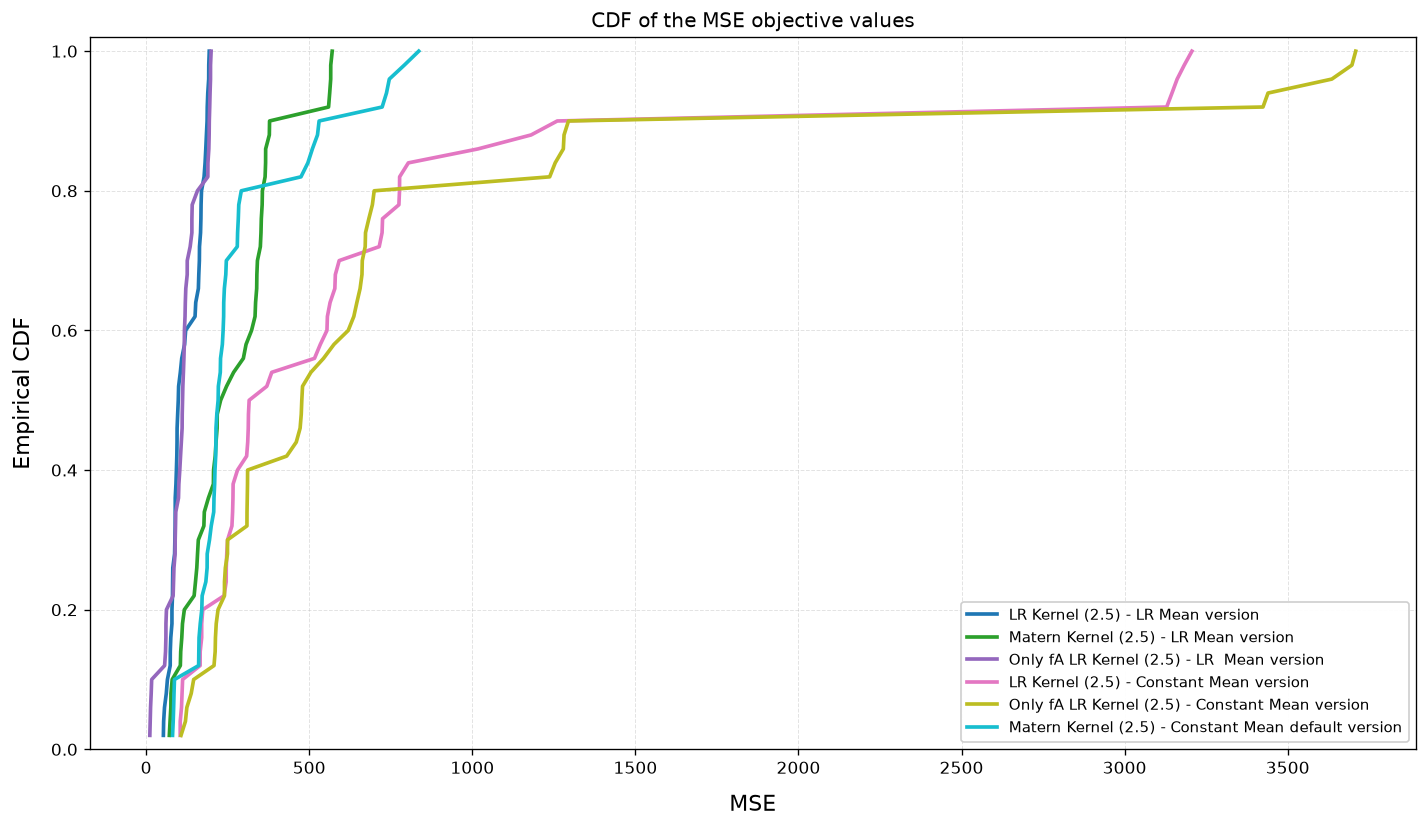

In [8]:
from scipy.stats import ecdf

method_names_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]

plt.figure(figsize=(12, 7), dpi=120)

colors = plt.cm.tab10(np.linspace(0, 1, len(method_names_list)))

for i, method_name in enumerate(method_names_list):

    df = torch.load(
        f"./validation/{method_name}_validation_original_df.pt",
        weights_only=False
    )

    df["nmse"]=df["mse"]/(np.square(corridors_df_gt["route_sum_average_traveltime"])).mean()

    # Calcul de la CDF empirique
    res = ecdf(df["mse"].values)

    plt.plot(
        res.cdf.quantiles,
        res.cdf.probabilities,
        label=method_name,
        color=colors[i],
        linewidth=2.2
    )

plt.xlabel("MSE", fontsize=13, labelpad=10)
plt.ylabel("Empirical CDF", fontsize=13, labelpad=10)

#plt.xlim(0, 2)  # Limite le NMSE à 10
plt.ylim(0, 1.02)

plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

plt.legend(loc="lower right", fontsize=9, framealpha=0.95)
plt.title("CDF of the MSE objective values")


plt.tight_layout()
plt.show()


81.0017051851852
152.89045570370368
81.0017051851852
(100, 10)


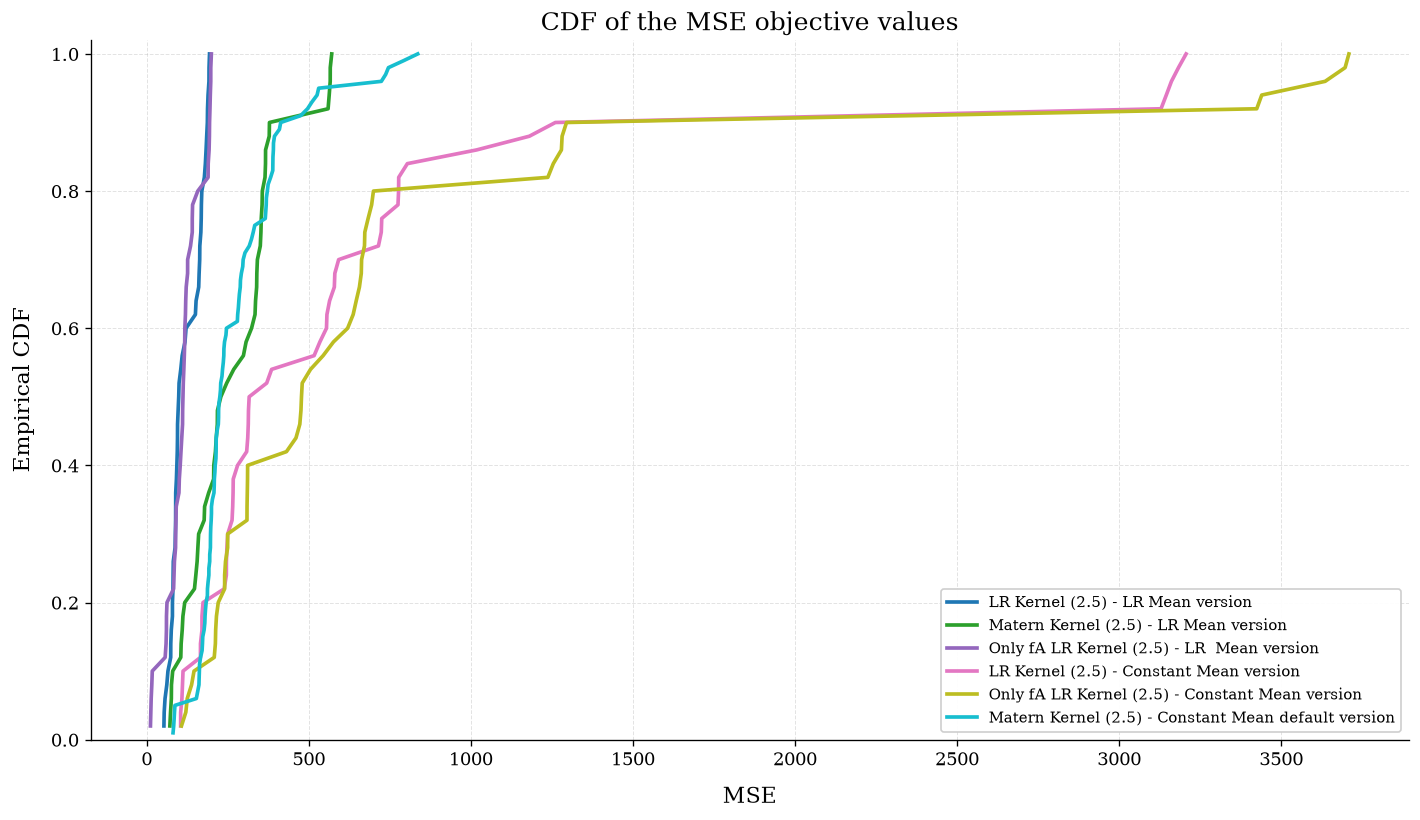

In [32]:
from scipy.stats import ecdf

method_names_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]

plt.figure(figsize=(12, 7), dpi=120)

colors = plt.cm.tab10(np.linspace(0, 1, len(method_names_list)))

for i, method_name in enumerate(method_names_list):

    df = torch.load(
        f"./validation/{method_name}_validation_original_df.pt",
        weights_only=False
    )

    if method_name=="Matern Kernel (2.5) - Constant Mean default version":
        df_2 = torch.load(
                f"./validation/{method_name}_validation_df.pt",
                weights_only=False
            )
        print(df["mse"].min())
        df=pd.concat([df,df_2],axis=0)

        print(df_2["mse"].min())
        print(df["mse"].min())
        print(df.shape)

    df["nmse"]=df["mse"]/(np.square(corridors_df_gt["route_sum_average_traveltime"])).mean()

    # Calcul de la CDF empirique
    res = ecdf(df["mse"].values)

    plt.plot(
        res.cdf.quantiles,
        res.cdf.probabilities,
        label=method_name,
        color=colors[i],
        linewidth=2.2
    )

plt.xlabel("MSE", fontsize=13, labelpad=10)
plt.ylabel("Empirical CDF", fontsize=13, labelpad=10)

#plt.xlim(0, 2)  # Limite le NMSE à 10
plt.ylim(0, 1.02)

plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

plt.legend(loc="lower right", fontsize=9, framealpha=0.95)
plt.title("CDF of the MSE objective values")


plt.tight_layout()
plt.show()


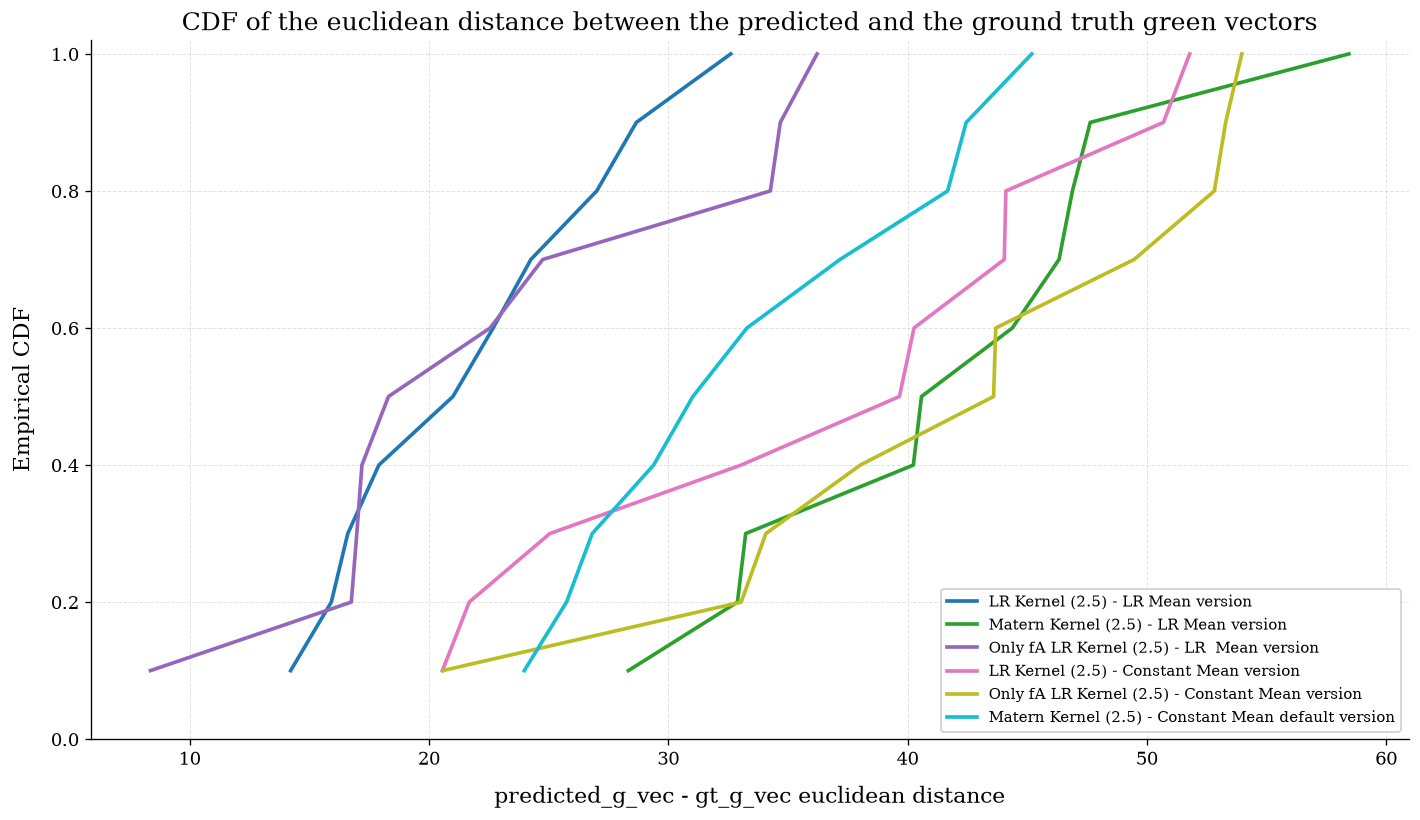

In [33]:
from scipy.stats import ecdf
from scipy.spatial.distance import euclidean


def compute_euclidean_distance(row):
    g_vec_gt=np.array([38,38,42,38,38,38,36])
    x=row[[f"g{i}" for i in range(7)]].values
    euclidean_distance=euclidean(x,g_vec_gt)
    return euclidean_distance

method_names_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]

plt.figure(figsize=(12, 7), dpi=120)

colors = plt.cm.tab10(np.linspace(0, 1, len(method_names_list)))

for i, method_name in enumerate(method_names_list):

    df = torch.load(
        f"./validation/{method_name}_validation_original_df.pt",
        weights_only=False
    )

    df["x_euclidean_distance"]=df.apply(compute_euclidean_distance,axis=1)

    # Calcul de la CDF empirique
    res = ecdf(df["x_euclidean_distance"].values)

    plt.plot(
        res.cdf.quantiles,
        res.cdf.probabilities,
        label=method_name,
        color=colors[i],
        linewidth=2.2
    )

plt.xlabel("predicted_g_vec - gt_g_vec euclidean distance", fontsize=13, labelpad=10)
plt.ylabel("Empirical CDF", fontsize=13, labelpad=10)

#plt.xlim(0, 2)  # Limite le NMSE à 10
plt.ylim(0, 1.02)

plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

plt.legend(loc="lower right", fontsize=9, framealpha=0.95)

plt.title("CDF of the euclidean distance between the predicted and the ground truth green vectors")

plt.tight_layout()
plt.show()


# BO with 20 iterations

# Only fA Linear Regression Kernel Linear Regression Mean

In [20]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 20  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [21]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [22]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)




bo_loop=BOLoop(niter=NITER,
               num_restart=NUM_RESTARTS,
               init_df=init_df,
               gp_initializer=gp_initializer,
               error_function=error_function,
               optimizer=optimizer,
               dtype=dtype,
               x_dim=X_DIM,
               loss_scale=SCALING_FACTOR_LOSS_FN,
               sample_size=INIT_SAMPLE_SIZE,
               output_dir=OUTPUT_DIR,
               bounds=bounds)

In [ ]:
bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["linear_regression"],annotation="nu_2.5_route_error_route_file_20iter_original")

# Default : Matern Kernel ConstantMean Mean

In [24]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 20  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [25]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [ ]:
bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["ConstantMean"],annotation="nu_2.5_route_error_route_file_20iter_original")

# Comparison 20 iterations

agg df for Only fA LR Kernel (2.5) - LR  Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,3988.066253,2705.002327
1,1.0,2446.566189,3328.668826
2,2.0,264.866833,100.854141
3,3.0,192.605444,118.102605
4,4.0,165.817470,80.572798
5,5.0,162.783185,75.146575
6,6.0,162.783185,75.146575
7,7.0,142.946401,48.902251
8,8.0,103.588517,33.406422
9,9.0,103.588517,33.406422


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,3988.066253,2705.002327
1,1.0,3467.021624,3167.265339
2,2.0,3467.021624,3167.265339
3,3.0,2424.040678,1926.776039
4,4.0,2414.367826,1922.279320
5,5.0,2377.092304,1973.656045
6,6.0,2283.111599,2077.895810
7,7.0,1784.637594,1444.997610
8,8.0,1784.637594,1444.997610
9,9.0,769.270214,1041.455476


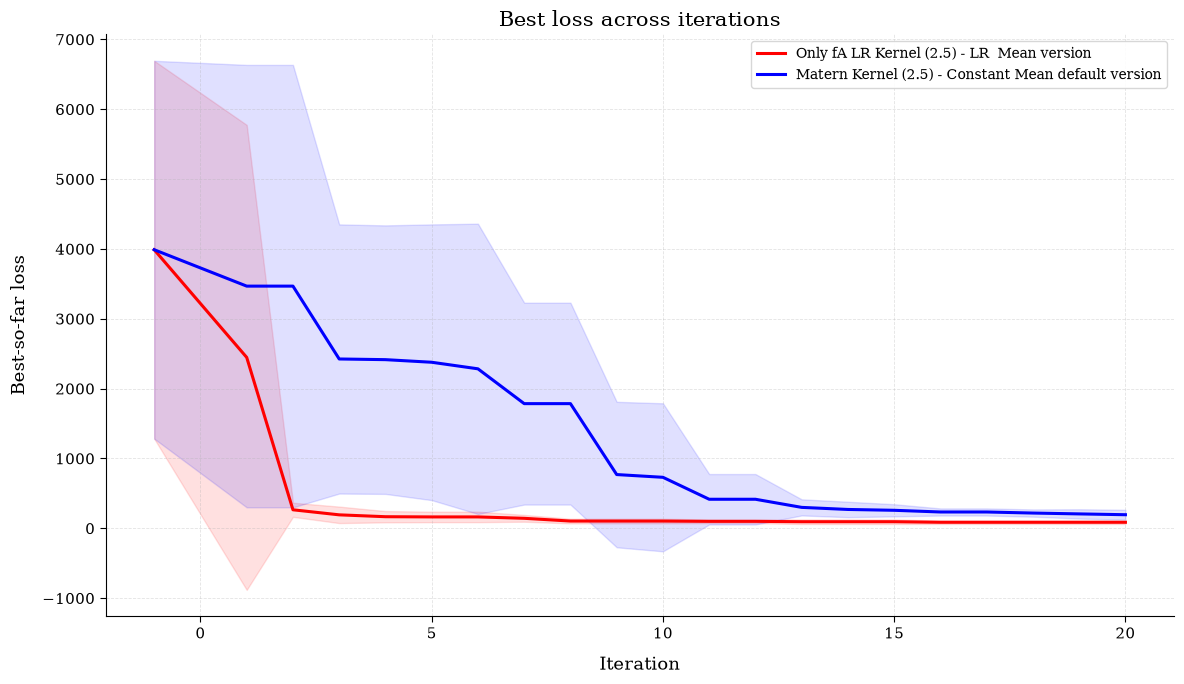

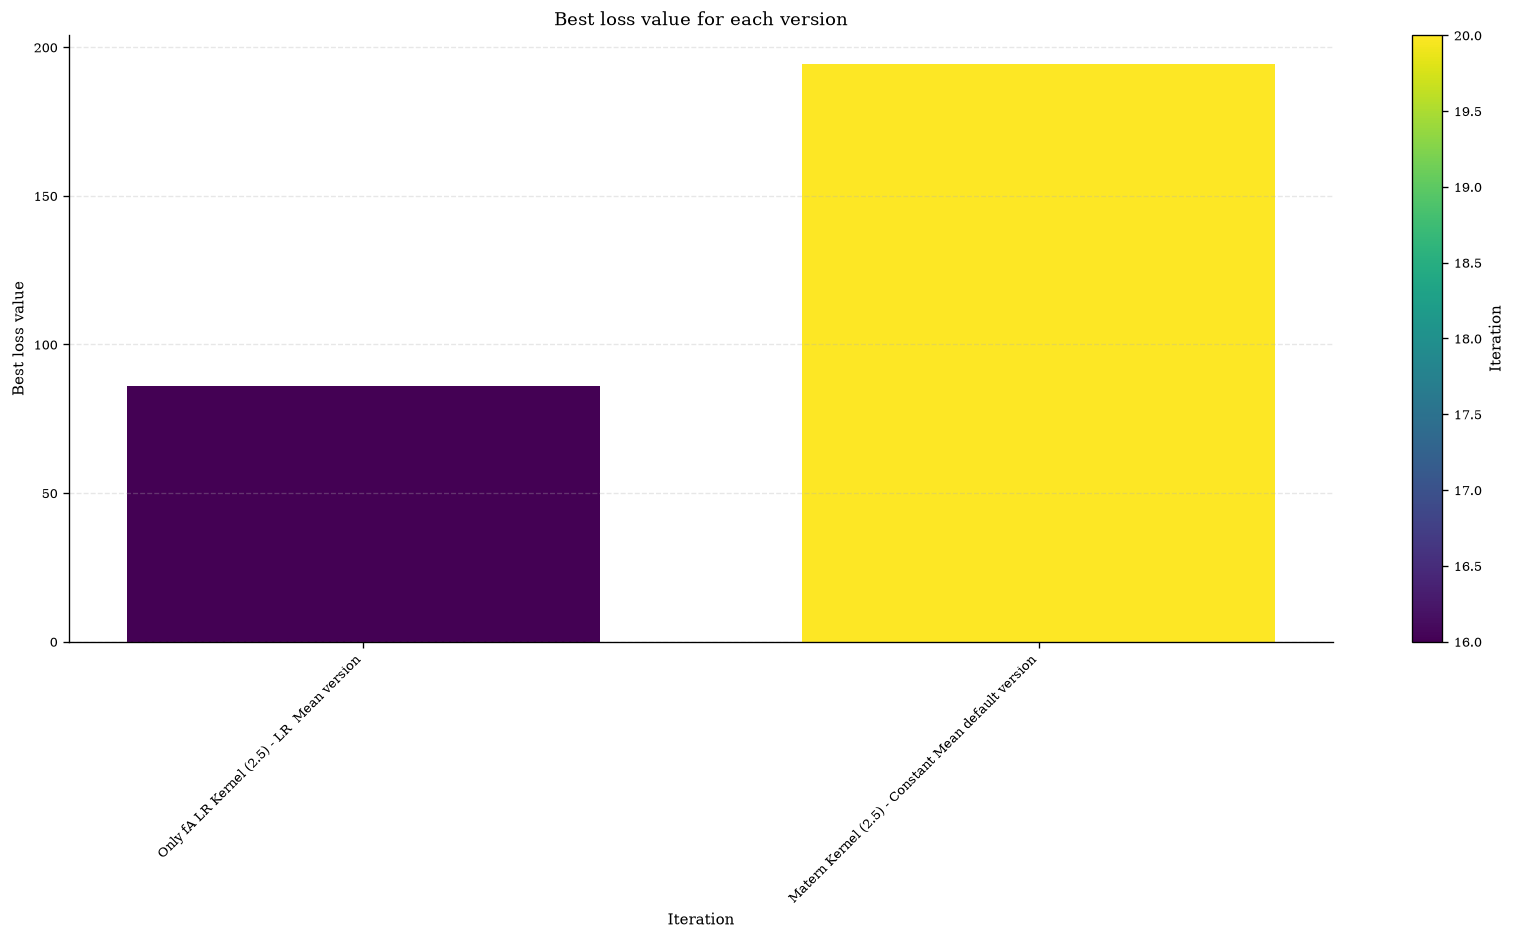

In [28]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "Only fA LR Kernel (2.5) - LR  Mean version": "red",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(5):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_20iter_original_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_20iter_original_restart"]

versions_list=[
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "Only fA LR Kernel (2.5) - LR  Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best-so-far loss", labelpad=10)
plt.title("Best loss across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Iteration", fontsize=9)
plt.ylabel("Best loss value", fontsize=9)
plt.title("Best loss value for each version", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Iteration", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# Using the same init samples for the restart

# Linear Regression Kernel ConstantMean Mean

In [2]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 3
NUM_RESTARTS_OPTI=5
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [3]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [ ]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS_OPTI,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)


for init_sample in range(3):
    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df[init_sample],
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)
    bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["ConstantMean"],annotation=f"nu_2.5_route_error_route_file_original_is{init_sample}")

# Linear Regression Kernel Linear Regression Mean

In [5]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 3
NUM_RESTARTS_OPTI=5
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [6]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [ ]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS_OPTI,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)


for init_sample in range(3):
    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df[init_sample],
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)
    bo_loop.run_loop(kernel_name_list=["linear_regression"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_original_is{init_sample}")

# Matern Kernel default Linear Regression Mean

In [8]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET

net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 3
NUM_RESTARTS_OPTI=5
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [9]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [ ]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS_OPTI,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)


for init_sample in range(3):
    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df[init_sample],
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)
    bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_original_is{init_sample}")

# Only fA Linear Regression Kernel Linear Regression Mean

In [11]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [12]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [ ]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS_OPTI,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)


for init_sample in range(3):
    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df[init_sample],
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)
    bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["linear_regression"],annotation=f"nu_2.5_route_error_route_file_original_is{init_sample}")

# Default version

In [14]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [15]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [ ]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS_OPTI,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)


for init_sample in range(3):
    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df[init_sample],
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)
    bo_loop.run_loop(kernel_name_list=["MaternKernel_default"],mean_name_list=["ConstantMean"],annotation=f"nu_2.5_route_error_route_file_original_is{init_sample}")

# Only fA Linear Regression Kernel ConstantMean Mean

In [17]:
GT_TRAVEL_TIME_PREFIX = 'gt_travel_times'
#SIM_TRAVEL_TIME_PREFIX = 'sim_travel_times'
ADD_XML = "ingolstadt7/additional.xml"

NET_XML="ingolstadt7/ingolstadt7.net.xml"

X_DIM = 7

SUMO_PATH = "/usr/local/opt/sumo/share/sumo"
#SUMO_PATH = "/usr/local/opt/sumo@1.18/share/sumo"
#"/usr/local/Cellar/sumo/1.18.0.reinstall/share/sumo"
NUM_REPLICATIONS = 5
GT_DIR = 'gt_data/'
OUTPUT_DIR = 'outputs/'

SCALING_FACTOR_LOSS_FN=1


def get_tls():
    green_phase_times_dict_tmp = update_green_time_dict(33*np.ones(X_DIM))
    tl_ids_set = []
    for elem in green_phase_times_dict_tmp.keys():
        if elem[0] not in tl_ids_set:
            tl_ids_set.append(elem[0])
    return tl_ids_set   

TL_IDS_SET = get_tls()
TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()

sumo_runner=SumoRun(
    add_xml=ADD_XML,
    gt_dir=GT_DIR,
    output_dir=OUTPUT_DIR,
    num_replications=NUM_REPLICATIONS,
    tl_ids_set=TL_IDS_SET
)

DF_GT = pd.read_csv(f'./gt_data/gt_route_file_travel_times.csv')
print(f'Number of GT edges: {DF_GT.shape[0]}')

DF_GT=get_freeflow_eta(DF_GT, 'ingolstadt7/ingolstadt7.net.xml')

error_function=ErrorFunctionRouteVersion(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,
                             df_gt=DF_GT,
                             sumo_runner=sumo_runner,
                             corridors_df=corridors_df)

#error_function=ErrorFunction(scaling_factor_loss_fn=SCALING_FACTOR_LOSS_FN,df_gt=DF_GT,sumo_runner=sumo_runner)


low_bound = 5
up_bound = 74
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
dtype = torch.double

bounds = torch.tensor([[low_bound]*X_DIM,
                       [up_bound]*(X_DIM-1)+[50]], 
                      device=device, dtype=dtype)

print(bounds)

# acquisition function parameters
BATCH_SIZE = 1
NUM_RESTARTS = 5 
RAW_SAMPLES = 32  # used to enhange the optimization of the acquisition fn
NITER = 10  #300
INIT_SAMPLE_SIZE = 5  #3

initial_sampler=InitialSamples(
    dtype=dtype
)

Number of GT edges: 92
tensor([[ 5.,  5.,  5.,  5.,  5.,  5.,  5.],
        [74., 74., 74., 74., 74., 74., 50.]], dtype=torch.float64)


In [18]:
init_sample_x_norm=torch.load("./init_samples/init_sample_x_norm_route_error_route_file.pt",weights_only=False)
init_sample_y=torch.load("./init_samples/init_sample_y_route_error_route_file.pt",weights_only=False)
init_df=torch.load("./init_samples/init_df_route_error_route_file.pt",weights_only=False)


tl_ids=TL_IDS_SET
net_xml="./ingolstadt7/ingolstadt7.net.xml"
route_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"

corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
g_dict_to_vary={
        "gneJ260":"GGGGGgrrr",
        "gneJ210": "GGggrrrrrrGGGG",
        "32564122": "GGGGGgrrr",
        "gneJ207":"GGgGrGGG",
        "gneJ143": "rrrGGGGgGGGg",
        "cluster_1757124350_1757124352":"GGgrrGGG",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"GGGGGGrrrrrr"
    }

g_dict_to_change={
        "gneJ260":"GrrrrrGGG",
        "gneJ210": "rrrrGGGGGGGGrr",
        "32564122": "GrrrrrGGG",
        "gneJ207":"rrrGGGrr",
        "gneJ143": "GGGGrrrrrrrr",
        "cluster_1757124350_1757124352":"rrrGGGrr",
        "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":"rrrrrrrrGGGG"
    }

g_dict_const={
    "gneJ260":["yyyyygrrr","rrrGGGrrr","rrryyyrrr","yrrrrryyy"],
    "gneJ210": ["yyggrrrrrryyyy","GGGGrrrrrrrrrr","yyyyrrrrrrrrrr","rrrryyyyyyyyrr"],
    "32564122": ["yyyyyyrrr","yrrrrryyy"],
    "gneJ207":["yygyryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "gneJ143": ["rrryyyygyyyg","rrrrrrrGrrrG","rrrrrrryrrry","yyyyrrrrrrrr"],
    "cluster_1757124350_1757124352":["yygrryyy","GGGrrrrr","yyyrrrrr","rrryyyrr"],
    "cluster_306484187_cluster_1200363791_1200363826_1200363834_1200363898_1200363927_1200363938_1200363947_1200364074_1200364103_1507566554_1507566556_255882157_306484190":["rrrrrrrrGGyy","rrrrrrGGGGrr","rrrrGGGGGGrr","rrrrGGyyyyrr","yyyyyyrrrrrr"]
}

dtype=torch.double

df_gt=DF_GT
corridors_generator=TLIncomingCorridors(net_xml,route_xml)
corridors_df=corridors_generator.get_corridors_df()
dtype=torch.double

net_xml="./ingolstadt7/ingolstadt7.net.xml"
routes_xml="./ingolstadt7/ingolstadt7_routes_with_edges.rou.xml"
corridors_generator=TLIncomingCorridors(net_xml,routes_xml)
corridors_df=corridors_generator.get_corridors_df()

complete_corridors_connexions_generator=CompleteCorridorsConnexions(routes_xml,net_xml,corridors_df)

complete_corridors_connexions_df=complete_corridors_connexions_generator.create_connexion_corridors_df()

connexions_routes_correspondance_tensor,connexions_routes_correspondance_df=connexions_routes_correspondance_matrix(complete_corridors_connexions_df)

connexions_green_time_creator=ConnexionsGreenTime(
    tl_ids=TL_IDS_SET,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    net_xml=net_xml,
    g_dict_to_change=g_dict_to_change,
    g_dict_to_vary=g_dict_to_vary,
    g_dict_const=g_dict_const,
    dtype=dtype
)

fA_function=UpdatedFAFunctionLinearRegresion(
    df_gt=DF_GT,
    corridors_df=corridors_df,
    complete_corridors_connexions_df=complete_corridors_connexions_df,
    connexions_green_time_extractor=connexions_green_time_creator,
    dtype=dtype,
    connexions_routes_correspondance_tensor=connexions_routes_correspondance_tensor
)

In [ ]:
gp_initializer=InitializeGPModel(
    fa_function=fA_function,
    bounds=bounds,
    dtype=dtype,
    rbf=False,
    nu=2.5,
    mean_mod=True
)

optimizer=Optimization(batch_size=BATCH_SIZE,
                       num_restarts=NUM_RESTARTS_OPTI,
                       device=device,
                       dtype=dtype,
                       raw_samples=RAW_SAMPLES)


for init_sample in range(3):
    bo_loop=BOLoop(niter=NITER,
                num_restart=NUM_RESTARTS,
                init_df=init_df[init_sample],
                gp_initializer=gp_initializer,
                error_function=error_function,
                optimizer=optimizer,
                dtype=dtype,
                x_dim=X_DIM,
                loss_scale=SCALING_FACTOR_LOSS_FN,
                sample_size=INIT_SAMPLE_SIZE,
                output_dir=OUTPUT_DIR,
                bounds=bounds)
    bo_loop.run_loop(kernel_name_list=["only_fA_linear_regression"],mean_name_list=["ConstantMean"],annotation=f"nu_2.5_route_error_route_file_original_is{init_sample}")

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,767.523833,0.000000
1,1.0,767.523833,0.000000
2,2.0,307.123223,399.718712
3,3.0,307.123223,399.718712
4,4.0,287.847152,415.412710
5,5.0,287.847152,415.412710
6,6.0,287.847152,415.412710
7,7.0,287.847152,415.412710
8,8.0,95.221959,81.778204
9,9.0,52.128698,7.165965


agg df for Matern Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,767.523833,0.000000
1,1.0,639.284290,222.117404
2,2.0,495.821887,236.406145
3,3.0,495.821887,236.406145
4,4.0,471.129955,193.882444
5,5.0,471.129955,193.882444
6,6.0,471.129955,193.882444
7,7.0,471.129955,193.882444
8,8.0,471.129955,193.882444
9,9.0,471.129955,193.882444


agg df for Only fA LR Kernel (2.5) - LR  Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,767.523833,0.000000
1,1.0,215.588251,168.985239
2,2.0,206.533056,176.219153
3,3.0,147.658970,74.248495
4,4.0,107.253021,4.326666
5,5.0,107.253021,4.326666
6,6.0,107.253021,4.326666
7,7.0,107.253021,4.326666
8,8.0,95.120026,16.772726
9,9.0,95.120026,16.772726


... (2 outputs left out)

agg df for Only fA LR Kernel (2.5) - Constant Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,767.523833,0.000000
1,1.0,624.523589,247.683688
2,2.0,624.523589,247.683688
3,3.0,581.120283,322.860418
4,4.0,581.120283,322.860418
5,5.0,581.120283,322.860418
6,6.0,581.120283,322.860418
7,7.0,450.758803,286.917529
8,8.0,450.758803,286.917529
9,9.0,450.758803,286.917529


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,767.523833,0.000000
1,1.0,767.523833,0.000000
2,2.0,767.523833,0.000000
3,3.0,767.523833,0.000000
4,4.0,644.393498,213.267995
5,5.0,644.393498,213.267995
6,6.0,481.847228,287.693538
7,7.0,481.847228,287.693538
8,8.0,304.377972,116.970969
9,9.0,304.377972,116.970969


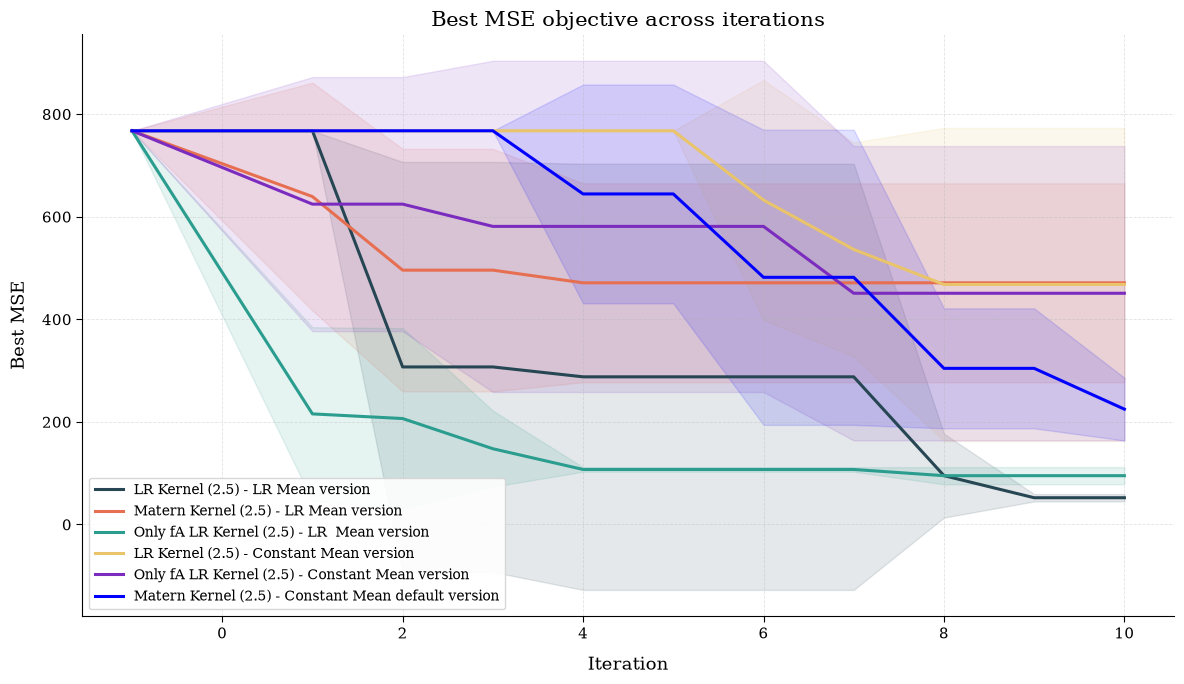

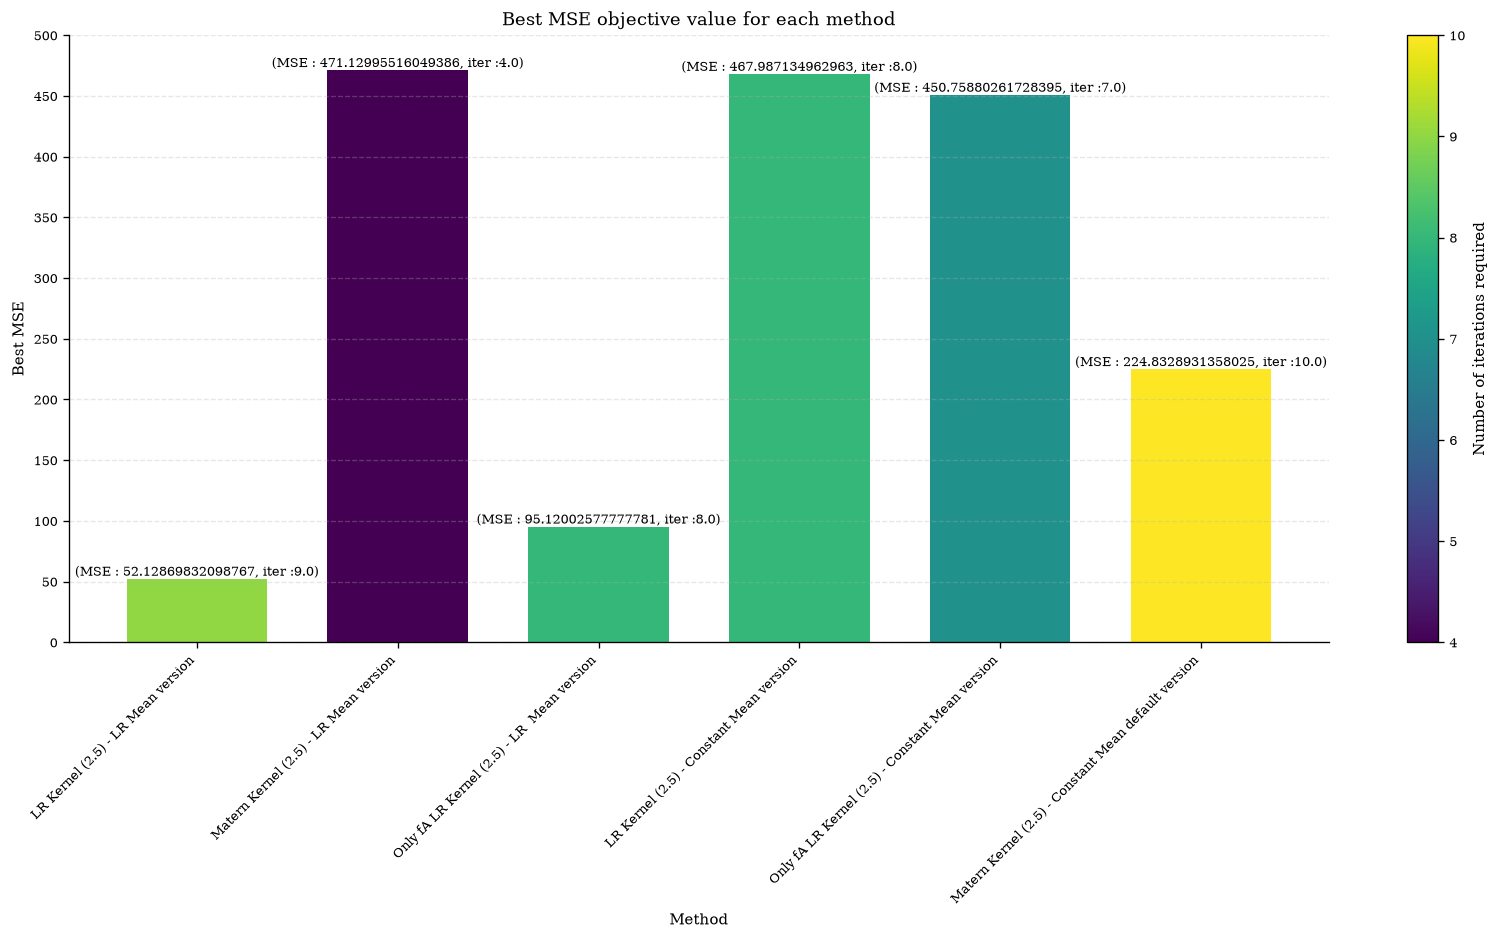

In [21]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - LR Mean version": "#E76F51",
    "Only fA LR Kernel (2.5) - LR  Mean version": "#2A9D8F",
    "LR Kernel (2.5) - Constant Mean version": "#E9C46A",
    "Only fA LR Kernel (2.5) - Constant Mean version": "#7B2CBF",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(3):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is0_restart",
            "outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_original_is0_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is0_restart",
            "outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_is0_restart",
            "outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_is0_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_is0_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - LR Mean version":0,
        "Only fA LR Kernel (2.5) - LR  Mean version":0,
        "LR Kernel (2.5) - Constant Mean version":0,
        "Only fA LR Kernel (2.5) - Constant Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

for bar, iteration, min_value in zip(bars, iterations, min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value}, iter :{iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Number of iterations required", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,7976.461660,0.000000
1,1.0,3685.558419,3942.995538
2,2.0,226.933727,26.573649
3,3.0,159.729950,37.986490
4,4.0,144.208355,54.917717
5,5.0,141.369737,50.359471
6,6.0,141.369737,50.359471
7,7.0,141.369737,50.359471
8,8.0,128.234479,30.740416
9,9.0,128.234479,30.740416


agg df for Matern Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,7976.461660,0.000000
1,1.0,1210.718126,1511.243188
2,2.0,295.981489,86.786312
3,3.0,295.981489,86.786312
4,4.0,295.981489,86.786312
5,5.0,295.981489,86.786312
6,6.0,273.163436,122.182681
7,7.0,260.194601,121.090788
8,8.0,260.194601,121.090788
9,9.0,235.008253,130.499348


agg df for Only fA LR Kernel (2.5) - LR  Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,7976.461660,0.000000
1,1.0,247.225398,184.054800
2,2.0,182.695706,92.291456
3,3.0,182.695706,92.291456
4,4.0,139.543772,17.655309
5,5.0,139.543772,17.655309
6,6.0,138.585060,18.700773
7,7.0,138.585060,18.700773
8,8.0,138.585060,18.700773
9,9.0,138.585060,18.700773


... (2 outputs left out)

agg df for Only fA LR Kernel (2.5) - Constant Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,7976.461660,0.000000
1,1.0,7290.993027,1187.266500
2,2.0,7290.993027,1187.266500
3,3.0,6505.195244,2548.308183
4,4.0,1826.514470,1504.537387
5,5.0,1826.514470,1504.537387
6,6.0,548.811114,310.732183
7,7.0,548.811114,310.732183
8,8.0,548.811114,310.732183
9,9.0,548.811114,310.732183


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,7976.461660,0.000000
1,1.0,7976.461660,0.000000
2,2.0,4109.313796,3835.675660
3,3.0,1818.766995,1969.409101
4,4.0,1691.851174,2049.079821
5,5.0,1027.498604,911.983426
6,6.0,416.779206,269.540330
7,7.0,416.779206,269.540330
8,8.0,416.779206,269.540330
9,9.0,416.779206,269.540330


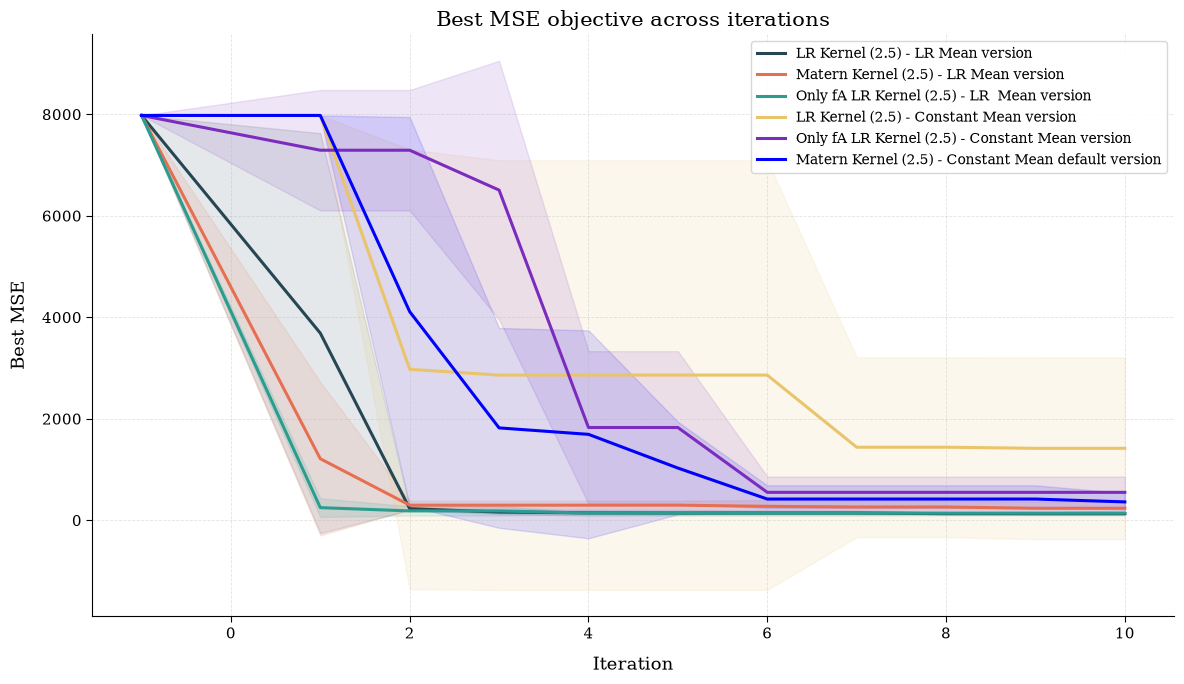

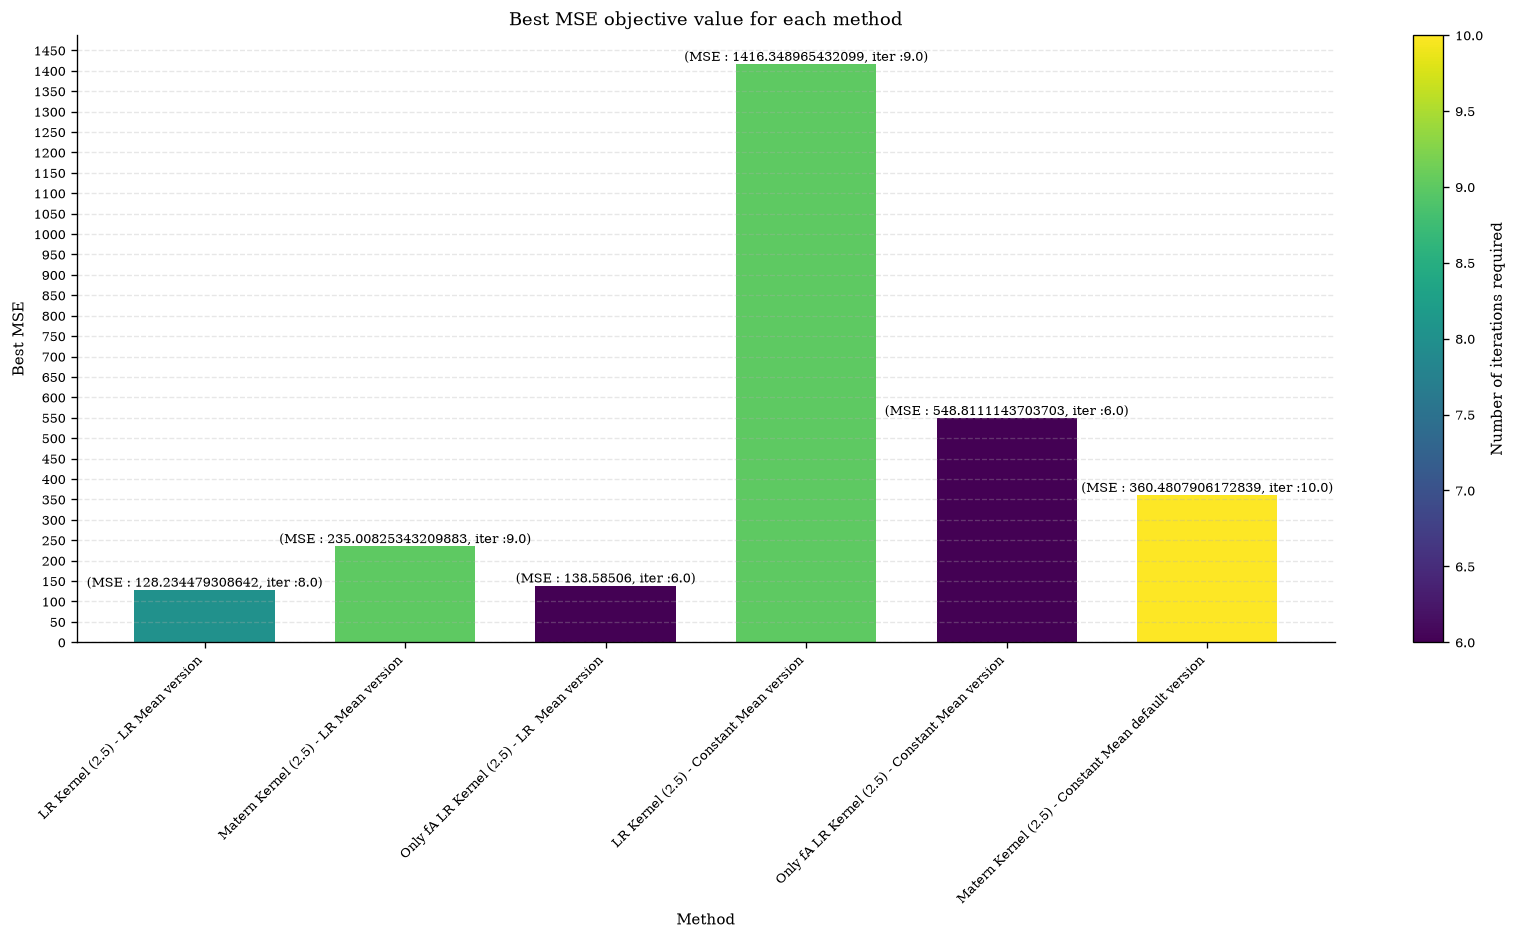

In [25]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - LR Mean version": "#E76F51",
    "Only fA LR Kernel (2.5) - LR  Mean version": "#2A9D8F",
    "LR Kernel (2.5) - Constant Mean version": "#E9C46A",
    "Only fA LR Kernel (2.5) - Constant Mean version": "#7B2CBF",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(3):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(agg_best_lost_df_all.iter, agg_best_lost_df_all.best_loss_mean, label=version,linewidth=2.2,color=colors[version])
    plt.fill_between(agg_best_lost_df_all.iter, 
                    agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std, 
                    agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std, 
                    alpha=0.12,color=colors[version])

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is1_restart",
            "outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_original_is1_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is1_restart",
            "outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_is1_restart",
            "outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_is1_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_is1_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - LR Mean version":0,
        "Only fA LR Kernel (2.5) - LR  Mean version":0,
        "LR Kernel (2.5) - Constant Mean version":0,
        "Only fA LR Kernel (2.5) - Constant Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

for bar, iteration, min_value in zip(bars, iterations, min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value}, iter :{iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Number of iterations required", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

agg df for LR Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,2946.240249,0.000000
1,1.0,1123.382712,1583.407299
2,2.0,1123.382712,1583.407299
3,3.0,206.053245,123.190623
4,4.0,206.053245,123.190623
5,5.0,206.053245,123.190623
6,6.0,105.802004,81.424163
7,7.0,79.651764,41.742611
8,8.0,79.651764,41.742611
9,9.0,79.651764,41.742611


agg df for Matern Kernel (2.5) - LR Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,2946.240249,0.000000
1,1.0,2030.531748,1586.053649
2,2.0,468.028736,310.741175
3,3.0,314.181247,102.749143
4,4.0,303.394514,99.272667
5,5.0,303.394514,99.272667
6,6.0,303.394514,99.272667
7,7.0,303.394514,99.272667
8,8.0,303.394514,99.272667
9,9.0,255.532544,57.634454


agg df for Only fA LR Kernel (2.5) - LR  Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,2946.240249,0.000000
1,1.0,1974.444142,1570.529262
2,2.0,1182.968268,1427.727151
3,3.0,431.435696,472.432046
4,4.0,178.292662,34.178535
5,5.0,178.292662,34.178535
6,6.0,178.292662,34.178535
7,7.0,126.632648,55.652252
8,8.0,126.632648,55.652252
9,9.0,100.687525,48.178322


... (2 outputs left out)

agg df for Only fA LR Kernel (2.5) - Constant Mean version


,iter,best_loss_mean,best_loss_std
0,-1.0,2946.240249,0.000000
1,1.0,2041.083588,1567.777325
2,2.0,2041.083588,1567.777325
3,3.0,2041.083588,1567.777325
4,4.0,2041.083588,1567.777325
5,5.0,2041.083588,1567.777325
6,6.0,1968.818447,1509.092002
7,7.0,1198.599340,1516.418208
8,8.0,1198.599340,1516.418208
9,9.0,1043.389819,1248.215784


agg df for Matern Kernel (2.5) - Constant Mean default version


,iter,best_loss_mean,best_loss_std
0,-1.0,2946.240249,0.000000
1,1.0,1729.061906,1282.815201
2,2.0,824.676888,892.725070
3,3.0,824.676888,892.725070
4,4.0,444.379171,415.249829
5,5.0,286.913809,144.297523
6,6.0,284.211045,145.877167
7,7.0,265.312016,168.567556
8,8.0,265.312016,168.567556
9,9.0,221.464343,198.717585


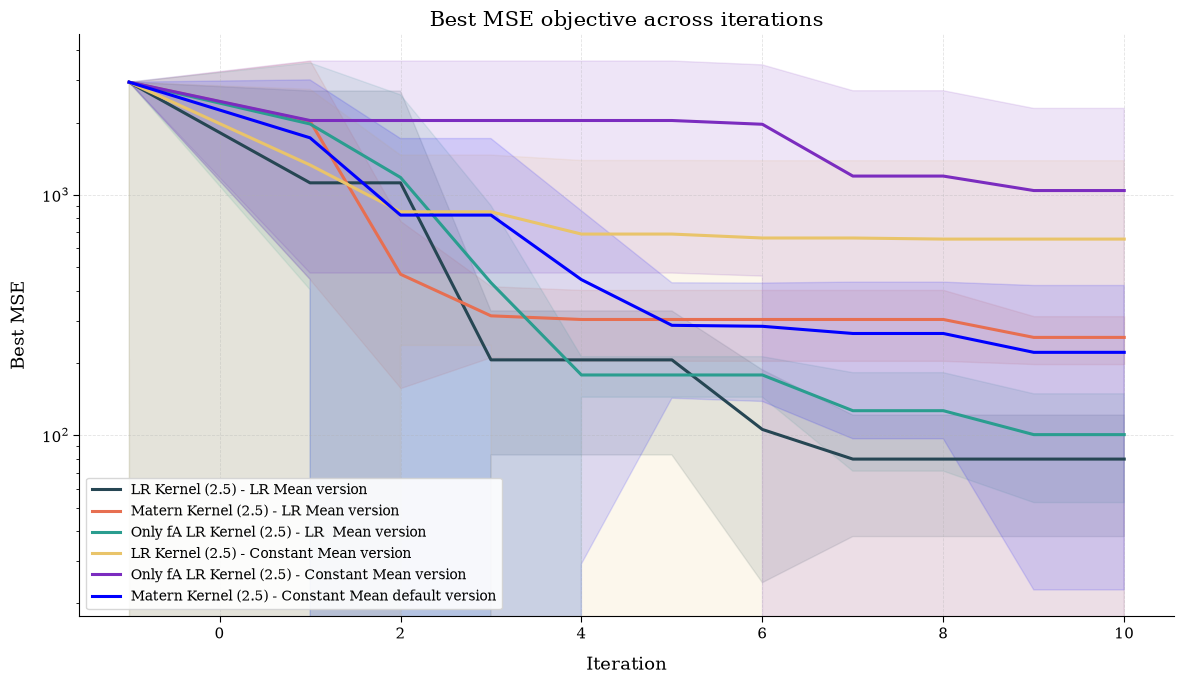

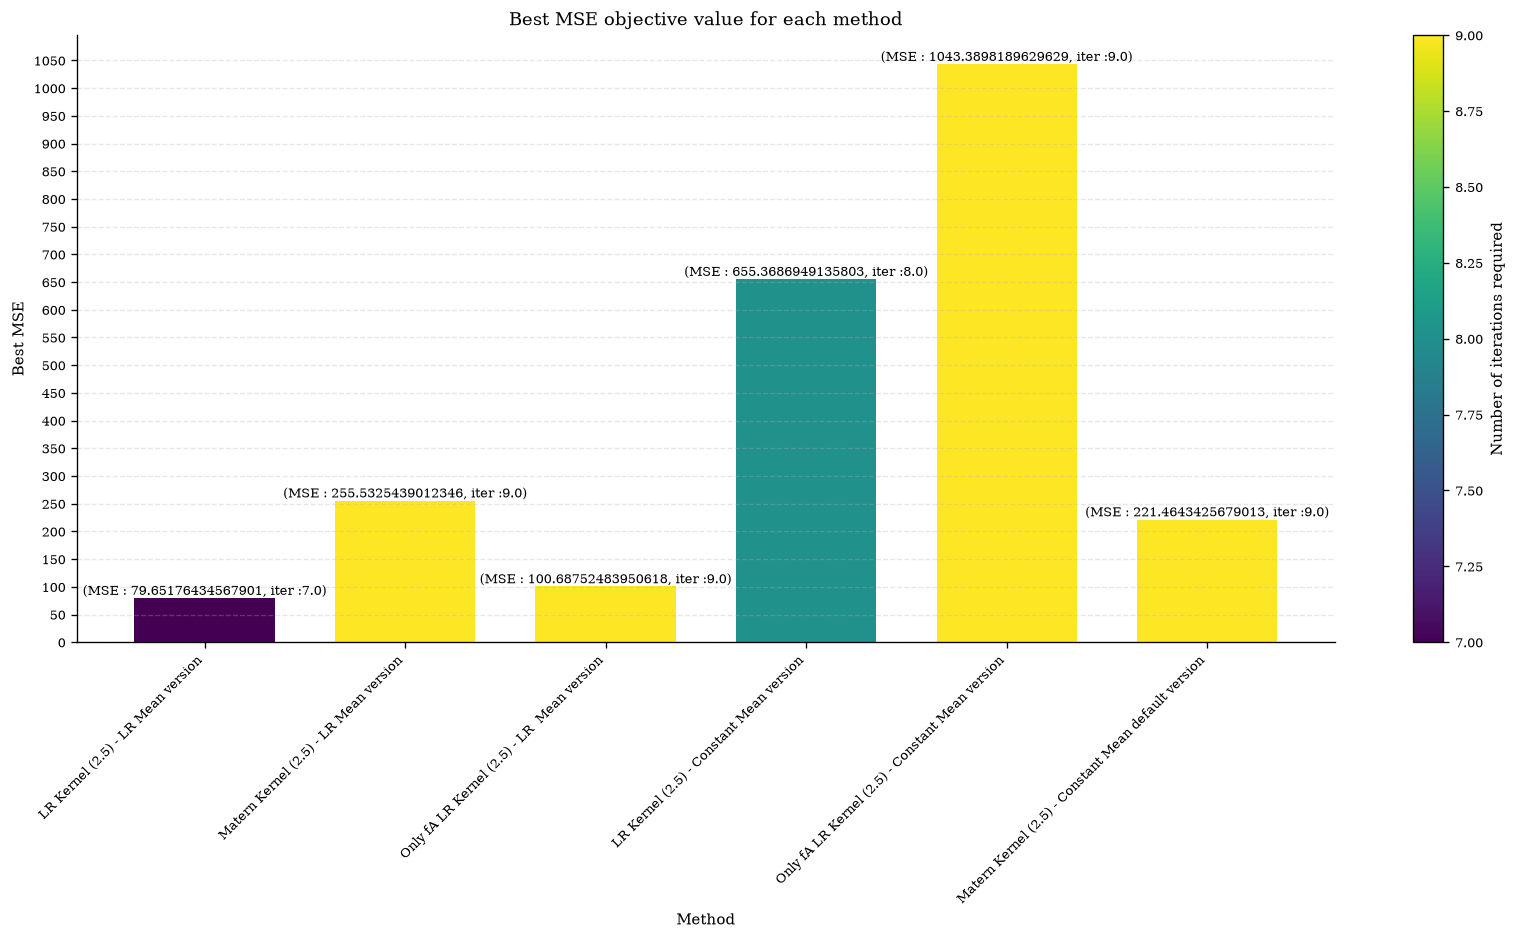

In [29]:

plt.figure(figsize=(12, 7))

# Esthétique générale
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 15,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



def GP_plot(path,version):

    colors = {
    "LR Kernel (2.5) - LR Mean version": "#264653",
    "Matern Kernel (2.5) - LR Mean version": "#E76F51",
    "Only fA LR Kernel (2.5) - LR  Mean version": "#2A9D8F",
    "LR Kernel (2.5) - Constant Mean version": "#E9C46A",
    "Only fA LR Kernel (2.5) - Constant Mean version": "#7B2CBF",
    "Matern Kernel (2.5) - Constant Mean default version": "blue"
    }

    best_lost_df_all=None
    for rs in range(3):
        df=pd.read_csv(f'{path}{rs}.csv')
        best_lost_df=df.groupby("iter").agg({"loss_estimate":"min"}).reset_index().rename(columns={"loss_estimate":"min_loss"})
        best_lost_df["min_loss"]=best_lost_df["min_loss"].cummin()
        if best_lost_df_all is None:
            best_lost_df_all=best_lost_df
        else:
            best_lost_df_all=pd.concat([best_lost_df_all,best_lost_df],axis=0)
    agg_best_lost_df_all=best_lost_df_all.groupby("iter").agg({"min_loss":["mean","std"]}).reset_index().droplevel(0,axis=1).rename(columns={"mean":"best_loss_mean","std":"best_loss_std","":"iter"})
    plt.plot(
    agg_best_lost_df_all.iter,
    agg_best_lost_df_all.best_loss_mean,
    label=version,
    linewidth=2.2,
    color=colors[version]
    )

    plt.fill_between(
        agg_best_lost_df_all.iter,
        agg_best_lost_df_all.best_loss_mean - agg_best_lost_df_all.best_loss_std,
        agg_best_lost_df_all.best_loss_mean + agg_best_lost_df_all.best_loss_std,
        alpha=0.12,
        color=colors[version]
    )

    plt.yscale('log')

    print(f"agg df for {version}")
    display(agg_best_lost_df_all)

    return agg_best_lost_df_all

paths_list=["outputs/BO_df_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is2_restart",
            "outputs/BO_df_MaternKernel_default_linear_regression_nu_2.5_route_error_route_file_original_is2_restart",
            "outputs/BO_df_only_fA_linear_regression_linear_regression_nu_2.5_route_error_route_file_original_is2_restart",
            "outputs/BO_df_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_is2_restart",
            "outputs/BO_df_only_fA_linear_regression_ConstantMean_nu_2.5_route_error_route_file_original_is2_restart",
            "outputs/BO_df_MaternKernel_default_ConstantMean_nu_2.5_route_error_route_file_original_is2_restart"]

versions_list=[
    "LR Kernel (2.5) - LR Mean version",
    "Matern Kernel (2.5) - LR Mean version",
    "Only fA LR Kernel (2.5) - LR  Mean version",
    "LR Kernel (2.5) - Constant Mean version",
    "Only fA LR Kernel (2.5) - Constant Mean version",
    "Matern Kernel (2.5) - Constant Mean default version"
]


version_min_values={
        "LR Kernel (2.5) - LR Mean version":0,
        "Matern Kernel (2.5) - LR Mean version":0,
        "Only fA LR Kernel (2.5) - LR  Mean version":0,
        "LR Kernel (2.5) - Constant Mean version":0,
        "Only fA LR Kernel (2.5) - Constant Mean version":0,
        "Matern Kernel (2.5) - Constant Mean default version":0
}

for path,version in zip(paths_list,versions_list):
    agg_best_lost_df_all=GP_plot(path,version)
    agg_best_lost_df_all=agg_best_lost_df_all.sort_values(by=["best_loss_mean","iter"])
    version_min_values[version]=(agg_best_lost_df_all.iloc[0]["best_loss_mean"],agg_best_lost_df_all.iloc[0]["iter"])


plt.xlabel("Iteration", labelpad=10)
plt.ylabel("Best MSE", labelpad=10)
plt.title("Best MSE objective across iterations")

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tick_params(axis="both", direction="out", length=4)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 8), dpi=120)

versions = list(version_min_values.keys())
min_values = [v[0] for v in version_min_values.values()]
iterations = np.array([v[1] for v in version_min_values.values()])

# Couleur proportionnelle à l'itération
norm = plt.Normalize(vmin=iterations.min(), vmax=iterations.max())
cmap = plt.cm.viridis
colors = cmap(norm(iterations))

bars = plt.bar(
    versions,
    min_values,
    color=colors,
    width=0.7
)

plt.xlabel("Method", fontsize=9)
plt.ylabel("Best MSE", fontsize=9)
plt.title("Best MSE objective value for each method", fontsize=11)

plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(
    np.arange(0, max(min_values) + 50, 50),
    fontsize=8
)

for bar, iteration, min_value in zip(bars, iterations, min_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"(MSE : {min_value}, iter :{iteration})",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Barre de couleur indiquant l'itération
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label("Number of iterations required", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()